# MODELO Capsule Net



In [2]:
from pathlib import Path

# Directorio raíz del proyecto
PROJECT_ROOT = Path.cwd()

# Datos locales
DATA_DIR = PROJECT_ROOT / "data"
IDRID_DIR = DATA_DIR / "IDRiD2"

# Archivos CSV
TRAIN_CSV = DATA_DIR / "train_split.csv"
VAL_CSV = DATA_DIR / "val_split.csv"

# Directorios de imágenes
TRAIN_IMAGES_DIR = IDRID_DIR / "IDRiD" / "train" / "images"
TEST_IMAGES_DIR = IDRID_DIR / "IDRiD" / "test" / "images" 

# Comprobar estructura
required_paths = [
    TRAIN_CSV,
    VAL_CSV,
    TRAIN_IMAGES_DIR,
    TEST_IMAGES_DIR
]

missing_paths = [
    path for path in required_paths
    if not path.exists()
]

if missing_paths:
    print("Faltan los siguientes archivos/directorios locales:")
    
    for path in missing_paths:
        print(f" - {path}")
    
    raise FileNotFoundError(
        "Completa la estructura local indicada antes de continuar."
    )

print("Proyecto local:", PROJECT_ROOT)
print("Dataset:", IDRID_DIR)
print("Configuración local correcta.")

Proyecto local: c:\Users\lauri\Documents\PROYECTO_FINAL
Dataset: c:\Users\lauri\Documents\PROYECTO_FINAL\data\IDRiD2
Configuración local correcta.


In [3]:
# 2. CONFIGURACIÓN
# Descomenta en Colab cuando los archivos estén en Google Drive:
# from google.colab import drive
# drive.mount("/content/drive")

TRAIN_CSV = "\\data\\train_split.csv"
VAL_CSV = "\\data\\val_split.csv"

# Incluye únicamente carpetas del conjunto de entrenamiento.
# No mezcles aquí imágenes de test con nombres repetidos.
TRAIN_IMAGE_ROOTS = [
    "\\data\\IDRiD2\\IDRiD\\train\\images"
]

OUTPUT_DIR = Path(
    "C:\\Users\\lauri\\Documents\\PROYECTO_FINAL\\modelos\\CapsuleNet"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IMG_SIZE = 224
BATCH_SIZE = 16
EPOCHS = 40
# Reducido de 3 a 2 para acelerar drásticamente el entrenamiento
ROUTING_ITERATIONS = 2
# Reducimos aún más el learning rate para un entrenamiento más suave
LEARNING_RATE = 1e-4
# Aumentamos agresivamente el weight decay para combatir el sobreajuste
WEIGHT_DECAY = 2e-3

# True elimina las imágenes precomputadas con volteo vertical.
EXCLUDE_VFLIP_FROM_TRAIN = True

BEST_MODEL_PATH = OUTPUT_DIR / "capsulenet_best_auc.keras"
FINAL_MODEL_PATH = OUTPUT_DIR / "capsulenet_final.keras"
HISTORY_CSV_PATH = OUTPUT_DIR / "capsulenet_history.csv"
THRESHOLD_PATH = OUTPUT_DIR / "capsulenet_thresholds.json"

In [4]:
from pathlib import Path

# ============================================================
# 2. CONFIGURACIÓN
# ============================================================

# Carpeta raíz real del proyecto
PROJECT_ROOT = Path(
    r"C:\Users\lauri\Documents\PROYECTO_FINAL"
)

# Carpeta de datos
DATA_DIR = PROJECT_ROOT / "data"

# CSV
TRAIN_CSV = DATA_DIR / "train_split.csv"
VAL_CSV = DATA_DIR / "val_split.csv"

# Incluye únicamente carpetas del conjunto de entrenamiento.
# No mezclar imágenes del test.
TRAIN_IMAGE_ROOTS = [
    DATA_DIR / "IDRiD2" / "IDRiD" / "train" / "images"
]

# Resultados del modelo CapsuleNet
OUTPUT_DIR = PROJECT_ROOT / "modelos" / "CapsuleNet"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# HIPERPARÁMETROS
# ============================================================

IMG_SIZE = 224
BATCH_SIZE = 16
EPOCHS = 40

ROUTING_ITERATIONS = 2

LEARNING_RATE = 1e-4
WEIGHT_DECAY = 2e-3

# True elimina las imágenes precomputadas con volteo vertical.
EXCLUDE_VFLIP_FROM_TRAIN = True

# ============================================================
# ARCHIVOS DE SALIDA
# ============================================================

BEST_MODEL_PATH = OUTPUT_DIR / "capsulenet_best_auc.keras"
FINAL_MODEL_PATH = OUTPUT_DIR / "capsulenet_final.keras"
HISTORY_CSV_PATH = OUTPUT_DIR / "capsulenet_history.csv"
THRESHOLD_PATH = OUTPUT_DIR / "capsulenet_thresholds.json"

In [5]:
from pathlib import Path

PROJECT_ROOT = Path(r"C:\Users\lauri\Documents\PROYECTO_FINAL")

DATA_DIR = PROJECT_ROOT / "data"

TRAIN_CSV = DATA_DIR / "train_split.csv"
VAL_CSV = DATA_DIR / "val_split.csv"

TRAIN_IMAGE_ROOTS = [
    DATA_DIR / "IDRiD2" / "IDRiD" / "train" / "images"
]

TEST_IMAGES_DIR = (
    DATA_DIR / "IDRiD2" / "IDRiD" / "test" / "images"
)

OUTPUT_DIR = PROJECT_ROOT / "modelos" / "CapsuleNet"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [6]:
import os
import shutil


# Crea la carpeta en el root
"""os.makedirs("/root/.kaggle", exist_ok=True)

# reconocimiento de las credenciales
if "kaggle.json" not in uploaded.keys():
    raise FileNotFoundError(
        "No se encontró kaggle.json. Vuelve a ejecutar la celda y selecciona ese archivo."
        )

# pegado en la carpeta
shutil.copy("kaggle.json", "/root/.kaggle/kaggle.json")
os.chmod("/root/.kaggle/kaggle.json", 0o600)


print("Credenciales de Kaggle configuradas correctamente.")"""

'os.makedirs("/root/.kaggle", exist_ok=True)\n\n# reconocimiento de las credenciales\nif "kaggle.json" not in uploaded.keys():\n    raise FileNotFoundError(\n        "No se encontró kaggle.json. Vuelve a ejecutar la celda y selecciona ese archivo."\n        )\n\n# pegado en la carpeta\nshutil.copy("kaggle.json", "/root/.kaggle/kaggle.json")\nos.chmod("/root/.kaggle/kaggle.json", 0o600)\n\n\nprint("Credenciales de Kaggle configuradas correctamente.")'

In [7]:
# 2. CONFIGURACIÓN
# Descomenta en Colab cuando los archivos estén en Google Drive:
# from google.colab import drive
# drive.mount("/content/drive")

TRAIN_CSV = "/data/train_split.csv"
VAL_CSV = "/data/val_split.csv"

# Incluye únicamente carpetas del conjunto de entrenamiento.
# No mezcles aquí imágenes de test con nombres repetidos.
TRAIN_IMAGE_ROOTS = [
    "/data/IDRiD2/IDRiD/train/images"
]

OUTPUT_DIR = Path(
    "/data/modelos/CapsuleNet"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IMG_SIZE = 224
BATCH_SIZE = 16
EPOCHS = 40
# Reducido de 3 a 2 para acelerar drásticamente el entrenamiento
ROUTING_ITERATIONS = 2
# Reducimos aún más el learning rate para un entrenamiento más suave
LEARNING_RATE = 1e-4
# Aumentamos agresivamente el weight decay para combatir el sobreajuste
WEIGHT_DECAY = 2e-3

# True elimina las imágenes precomputadas con volteo vertical.
EXCLUDE_VFLIP_FROM_TRAIN = True

BEST_MODEL_PATH = OUTPUT_DIR / "capsulenet_best_auc.keras"
FINAL_MODEL_PATH = OUTPUT_DIR / "capsulenet_final.keras"
HISTORY_CSV_PATH = OUTPUT_DIR / "capsulenet_history.csv"
THRESHOLD_PATH = OUTPUT_DIR / "capsulenet_thresholds.json"


In [8]:


import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import gc
import json
import math
import random
import shutil
import hashlib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve,
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras import mixed_precision

warnings.filterwarnings("ignore")

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

GPUS = tf.config.list_physical_devices("GPU")

for gpu in GPUS:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass

if GPUS:
    mixed_precision.set_global_policy("mixed_float16")
else:
    mixed_precision.set_global_policy("float32")

print("TensorFlow:", tf.__version__)
print("GPU disponibles:", GPUS)
print("Política de precisión:", mixed_precision.global_policy())

TensorFlow: 2.21.0
GPU disponibles: []
Política de precisión: <DTypePolicy "float32">


In [9]:
CLASS_NAMES = {
    0: "No referible",
    1: "Referible",
}

IMG_HEIGHT = 224
IMG_WIDTH = 224
IMG_SIZE = (IMG_HEIGHT,IMG_WIDTH)

# Ajuste automático según el hardware local.
BATCH_SIZE=32 if GPUS else 8

HEAD_EPOCHS = 8
FINE_TUNE_EPOCHS = 12

HEAD_LEARNING_RATE = 1e-3
FINE_TUNE_LEARNING_RATE = 3e-5

UNFREEZE_LAST_LAYERS = 40
DROPOUT_RATE = 0.35

# La caché guarda las imágenes redimensionadas en disco.
USE_DISK_CACHE = True

# Puede activarse si el entorno soporta XLA sin errores.
JIT_COMPILE = False

WORK_ROOT = PROJECT_ROOT

RUN_DIR = WORK_ROOT /"modelos\\CapsuleNet_rdr"
CACHE_DIR = RUN_DIR / "tf_cache"
LOG_DIR = RUN_DIR / "logs"

RUN_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)

HEAD_MODEL_PATH = RUN_DIR / "efficientnetb0_head_best.keras"
FINETUNE_MODEL_PATH = RUN_DIR / "efficientnetb0_finetuned_best.keras"
FINAL_MODEL_PATH = RUN_DIR / "efficientnetb0_rdr_final.keras"

HISTORY_PATH = RUN_DIR / "historial_entrenamiento.csv"
METRICS_PATH = RUN_DIR / "metricas_validacion.json"
THRESHOLD_PATH = RUN_DIR / "umbral_clasificacion.json"
VALIDATION_PREDICTIONS_PATH = RUN_DIR / "predicciones_validacion.csv"
DASHBOARD_PATH = RUN_DIR / "dashboard_efficientnetb0.html"

print("Directorio de resultados:", RUN_DIR)
print("Tamaño de imagen:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

Directorio de resultados: C:\Users\lauri\Documents\PROYECTO_FINAL\modelos\CapsuleNet_rdr
Tamaño de imagen: (224, 224)
Batch size: 8


In [17]:


from pathlib import Path
import pandas as pd

# ============================================================
# RUTAS LOCALES DEL PROYECTO
# ============================================================

PROJECT_ROOT = Path(
    r"C:\Users\lauri\Documents\PROYECTO_FINAL"
)

DATA_DIR = PROJECT_ROOT / "data"

# Archivos CSV
TRAIN_CSV = DATA_DIR / "train_split.csv"
VAL_CSV = DATA_DIR / "val_split.csv"

# ============================================================
# VERIFICAR RUTAS
# ============================================================

print("TRAIN_CSV:")
print(TRAIN_CSV)

print("\nVAL_CSV:")
print(VAL_CSV)

print("\n¿Existe TRAIN_CSV?:", TRAIN_CSV.exists())
print("¿Existe VAL_CSV?:", VAL_CSV.exists())

# ============================================================
# DETENER SI FALTAN
# ============================================================

missing_files = [
    path
    for path in [TRAIN_CSV, VAL_CSV]
    if not path.exists()
]

if missing_files:
    print("\nFaltan los siguientes archivos:")

    for path in missing_files:
        print(f" - {path}")

    raise FileNotFoundError(
        "No se encontraron los CSV en la carpeta data."
    )

print("\nRutas CSV correctas.")

TRAIN_CSV:
C:\Users\lauri\Documents\PROYECTO_FINAL\data\train_split.csv

VAL_CSV:
C:\Users\lauri\Documents\PROYECTO_FINAL\data\val_split.csv

¿Existe TRAIN_CSV?: True
¿Existe VAL_CSV?: True

Rutas CSV correctas.


In [18]:
# 3. CARGAR Y AUDITAR LOS MANIFIESTOS

REQUIRED_COLUMNS = {"Image name", "binary_label", "patient_id"}

train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_csv(VAL_CSV)

for dataset_name, frame in [("train", train_df), ("val", val_df)]:
    missing = REQUIRED_COLUMNS - set(frame.columns)
    if missing:
        raise ValueError(
            f"Faltan columnas en {dataset_name}: {sorted(missing)}"
        )

    frame["Image name"] = frame["Image name"].astype(str).str.strip()
    frame["patient_id"] = frame["patient_id"].astype(str).str.strip()
    frame["binary_label"] = frame["binary_label"].astype(int)

    invalid = set(frame["binary_label"].unique()) - {0, 1}
    if invalid:
        raise ValueError(
            f"Etiquetas inválidas en {dataset_name}: {invalid}"
        )

patient_overlap = set(train_df["patient_id"]) & set(val_df["patient_id"])
if patient_overlap:
    raise ValueError(
        "Existe fuga de pacientes entre train y validación: "
        f"{sorted(patient_overlap)[:10]}"
    )

if EXCLUDE_VFLIP_FROM_TRAIN:
    previous_size = len(train_df)
    train_df = train_df[
        ~train_df["Image name"].str.endswith("_VFLIP", na=False)
    ].reset_index(drop=True)
    print("VFLIP excluidos:", previous_size - len(train_df))

print("Train:", train_df.shape)
print(train_df["binary_label"].value_counts().sort_index())
print("Pacientes train:", train_df["patient_id"].nunique())

print("\nValidación:", val_df.shape)
print(val_df["binary_label"].value_counts().sort_index())
print("Pacientes val:", val_df["patient_id"].nunique())

VFLIP excluidos: 330
Train: (2310, 9)
binary_label
0     861
1    1449
Name: count, dtype: int64
Pacientes train: 330

Validación: (83, 9)
binary_label
0    31
1    52
Name: count, dtype: int64
Pacientes val: 83


In [19]:
# ============================================================
# 4. RESOLVER RUTAS DE IMÁGENES SIN MEZCLAR TRAIN Y TEST
# ============================================================

from pathlib import Path


VALID_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".tif",
    ".tiff",
    ".bmp",
}


# ============================================================
# CREAR ÍNDICE DE IMÁGENES
# ============================================================

def build_image_index(roots):

    index = {}
    duplicates = {}

    for root in roots:

        root = Path(root)

        if not root.exists():

            raise FileNotFoundError(
                f"No existe la carpeta:\n{root}"
            )

        if not root.is_dir():

            raise NotADirectoryError(
                f"La ruta no es una carpeta:\n{root}"
            )


        for path in root.rglob("*"):

            if not path.is_file():
                continue

            if path.suffix.lower() not in VALID_EXTENSIONS:
                continue


            # Usamos solo el nombre sin extensión
            # y en minúsculas para evitar diferencias
            # entre CSV y archivos reales.
            stem = (
                path.stem
                .strip()
                .lower()
            )


            absolute_path = str(
                path.resolve()
            )


            if (
                stem in index
                and
                index[stem] != absolute_path
            ):

                duplicates.setdefault(
                    stem,
                    [index[stem]]
                )

                duplicates[stem].append(
                    absolute_path
                )

            else:

                index[stem] = absolute_path


    # ========================================================
    # DETECTAR DUPLICADOS
    # ========================================================

    if duplicates:

        examples = list(
            duplicates.items()
        )[:10]


        details = "\n".join(

            f"{name}:\n"
            + "\n".join(
                f"   - {path}"
                for path in paths
            )

            for name, paths
            in examples
        )


        raise ValueError(

            "\nSe encontraron nombres de imagen duplicados "
            "dentro de las carpetas indexadas.\n\n"

            "Esto puede provocar fuga de datos o asignaciones "
            "ambiguas.\n\n"

            f"Ejemplos:\n{details}"
        )


    return index


# ============================================================
# ASIGNAR RUTAS A CADA MANIFIESTO
# ============================================================

def attach_paths(
    frame,
    image_index,
    dataset_name="dataset",
):

    result = frame.copy()


    # --------------------------------------------------------
    # Normalizar nombre de imagen del CSV
    # --------------------------------------------------------
    #
    # Esto funciona tanto si el CSV contiene:
    #
    # IDRiD_001
    #
    # como:
    #
    # IDRiD_001.jpg
    #
    # --------------------------------------------------------

    result["_image_key"] = (

        result["Image name"]
        .astype(str)
        .map(
            lambda value:
            Path(value.strip()).stem.lower()
        )
    )


    # --------------------------------------------------------
    # Buscar ruta
    # --------------------------------------------------------

    result["image_path"] = (
        result["_image_key"]
        .map(image_index)
    )


    # --------------------------------------------------------
    # Detectar imágenes no encontradas
    # --------------------------------------------------------

    missing_mask = (
        result["image_path"].isna()
    )


    missing = result.loc[
        missing_mask,
        "Image name",
    ].tolist()


    if missing:

        print("\n" + "=" * 80)

        print(
            f"IMÁGENES NO ENCONTRADAS EN {dataset_name.upper()}"
        )

        print("=" * 80)

        print(
            f"Total no encontradas: {len(missing)}"
        )

        print(
            "\nPrimeros ejemplos:"
        )


        for name in missing[:20]:

            print(
                f" - {name}"
            )


        raise FileNotFoundError(

            f"\nNo se pudieron resolver "
            f"{len(missing)} imágenes "
            f"del manifiesto {dataset_name}."
        )


    # Eliminar columna auxiliar
    result = result.drop(
        columns=["_image_key"]
    )


    return result


# ============================================================
# INDEXAR SOLO LAS IMÁGENES DE TRAIN
# ============================================================
#
# IMPORTANTE:
#
# train_df y val_df pertenecen al split de desarrollo,
# por lo tanto ambos deben buscarse únicamente dentro
# del conjunto de imágenes de entrenamiento.
#
# NO incluimos TEST_IMAGES_DIR aquí.
#
# ============================================================

TRAIN_IMAGE_ROOTS = [
    TRAIN_IMAGES_DIR
]


image_index = build_image_index(
    TRAIN_IMAGE_ROOTS
)


# ============================================================
# RESOLVER RUTAS PARA TRAIN Y VALIDACIÓN
# ============================================================

train_df = attach_paths(
    train_df,
    image_index,
    dataset_name="train",
)


val_df = attach_paths(
    val_df,
    image_index,
    dataset_name="validación",
)


# ============================================================
# COMPROBACIONES FINALES
# ============================================================

print("\n" + "=" * 80)

print(
    "RESOLUCIÓN DE RUTAS COMPLETADA"
)

print("=" * 80)


print(
    f"Imágenes indexadas: "
    f"{len(image_index):,}"
)


print(
    f"Rutas resueltas en TRAIN: "
    f"{train_df['image_path'].notna().sum():,}"
)


print(
    f"Rutas resueltas en VALIDACIÓN: "
    f"{val_df['image_path'].notna().sum():,}"
)


print(
    "\nTodas las rutas fueron resueltas "
    "sin utilizar imágenes de TEST."
)


print("=" * 80)


RESOLUCIÓN DE RUTAS COMPLETADA
Imágenes indexadas: 3,304
Rutas resueltas en TRAIN: 2,310
Rutas resueltas en VALIDACIÓN: 83

Todas las rutas fueron resueltas sin utilizar imágenes de TEST.


In [20]:
# 5. VALIDACIÓN ORIGINAL PARA SELECCIONAR EL MODELO

AUGMENTATION_SUFFIXES = r"_(R8|R16|R22|L6|L14|L20|VFLIP)$"

val_original_df = val_df[
    ~val_df["Image name"].str.contains(
        AUGMENTATION_SUFFIXES,
        regex=True,
        na=False,
    )
].copy()

if val_original_df.empty:
    val_original_df = (
        val_df.sort_values("Image name")
        .groupby("patient_id", as_index=False)
        .first()
    )

if val_original_df["patient_id"].duplicated().any():
    raise ValueError(
        "Hay más de una imagen original por paciente en validación."
    )

print("Imágenes de validación para callbacks:", len(val_original_df))
print(val_original_df["binary_label"].value_counts().sort_index())

Imágenes de validación para callbacks: 83
binary_label
0    31
1    52
Name: count, dtype: int64


In [21]:
# 6. PESOS DE CLASE

class_counts = (
    train_df["binary_label"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
    .astype(float)
)

if (class_counts == 0).any():
    raise ValueError("Ambas clases deben existir en entrenamiento.")

total = class_counts.sum()
class_weights = {
    class_id: total / (2.0 * count)
    for class_id, count in class_counts.items()
}

CLASS_WEIGHT_TENSOR = tf.constant(
    [class_weights[0], class_weights[1]],
    dtype=tf.float32,
)

print("Pesos:", class_weights)

Pesos: {0: np.float64(1.3414634146341464), 1: np.float64(0.7971014492753623)}


#PIPLENE

In [53]:
# 7. PREPROCESAMIENTO Y TF.DATA

AUTOTUNE = tf.data.AUTOTUNE

# Data Augmentation moderado para evitar deformaciones excesivas
data_augmentation = tf.keras.Sequential(
    [
        tf.keras.layers.RandomFlip("horizontal", seed=SEED - 1),
        tf.keras.layers.RandomRotation(
            0.05,
            fill_mode="reflect",
            seed=SEED,
        ),
        tf.keras.layers.RandomZoom(
            height_factor=(-0.05, 0.05),
            width_factor=(-0.05, 0.05),
            fill_mode="reflect",
            seed=SEED + 1,
        ),
        tf.keras.layers.RandomTranslation(
            height_factor=0.05,
            width_factor=0.05,
            fill_mode="reflect",
            seed=SEED + 2,
        ),
        tf.keras.layers.RandomContrast(
            factor=0.1,
            seed=SEED + 3,
        ),
    ],
    name="moderate_augmentation",
)

def crop_black_borders(image, threshold=10.0):
    image_float = tf.cast(image, tf.float32)
    gray = tf.reduce_mean(image_float, axis=-1)
    coordinates = tf.where(gray > threshold)

    def crop():
        y_min = tf.reduce_min(coordinates[:, 0])
        y_max = tf.reduce_max(coordinates[:, 0])
        x_min = tf.reduce_min(coordinates[:, 1])
        x_max = tf.reduce_max(coordinates[:, 1])
        return image[y_min:y_max + 1, x_min:x_max + 1, :]

    return tf.cond(
        tf.shape(coordinates)[0] > 0,
        crop,
        lambda: image,
    )

def decode_and_preprocess(path):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False,
    )
    image.set_shape([None, None, 3])

    # OPTIMIZACIÓN: Desactivado el recorte dinámico ya que tf.where
    # causa cuellos de botella masivos en la tubería tf.data.
    # image = crop_black_borders(image)

    image = tf.image.resize(
        image,
        IMG_SIZE,
        antialias=True,
    )
    image = tf.cast(image, tf.float32) / 255.0
    return tf.clip_by_value(image, 0.0, 1.0)

def load_training_sample(path, label):
    image = decode_and_preprocess(path)
    label = tf.cast(label, tf.int32)
    one_hot = tf.one_hot(label, 2, dtype=tf.float32)
    sample_weight = tf.gather(CLASS_WEIGHT_TENSOR, label)
    return image, one_hot, sample_weight

def load_validation_sample(path, label):
    image = decode_and_preprocess(path)
    label = tf.cast(label, tf.int32)
    one_hot = tf.one_hot(label, 2, dtype=tf.float32)
    return image, one_hot

def augment_batch(images, labels, weights):
    images = data_augmentation(images, training=True)
    return images, labels, weights

def make_training_dataset(frame):
    dataset = tf.data.Dataset.from_tensor_slices(
        (
            frame["image_path"].astype(str).values,
            frame["binary_label"].astype(np.int32).values,
        )
    )
    # 1. Mapear para procesar las imágenes una vez
    dataset = dataset.map(
        load_training_sample,
        num_parallel_calls=AUTOTUNE,
        deterministic=False,
    )
    # 2. Guardar en memoria caché antes del shuffle y los batches
    dataset = dataset.cache()
    # 3. Barajar (shuffle) de forma rápida con los datos ya procesados
    dataset = dataset.shuffle(
        len(frame),
        seed=SEED,
        reshuffle_each_iteration=True,
    )
    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.map(
        augment_batch,
        num_parallel_calls=AUTOTUNE,
        deterministic=False,
    )
    return dataset.prefetch(AUTOTUNE)

def make_validation_dataset(frame):
    dataset = tf.data.Dataset.from_tensor_slices(
        (
            frame["image_path"].astype(str).values,
            frame["binary_label"].astype(np.int32).values,
        )
    )
    dataset = dataset.map(
        load_validation_sample,
        num_parallel_calls=AUTOTUNE,
        deterministic=True,
    )
    # Aplicar caché también en validación
    dataset = dataset.cache()
    dataset = dataset.batch(BATCH_SIZE)
    return dataset.prefetch(AUTOTUNE)

def make_prediction_dataset(frame):
    dataset = tf.data.Dataset.from_tensor_slices(
        frame["image_path"].astype(str).values
    )
    dataset = dataset.map(
        decode_and_preprocess,
        num_parallel_calls=AUTOTUNE,
        deterministic=True,
    )
    dataset = dataset.batch(BATCH_SIZE)
    return dataset.prefetch(AUTOTUNE)

train_ds = make_training_dataset(train_df)
val_monitor_ds = make_validation_dataset(val_original_df)

images, labels, weights = next(iter(train_ds))
print(images.shape, labels.shape, weights.shape)


(8, 224, 224, 3) (8, 2) (8,)


REVISION DE UN SOLO LOTE

Forma de las imágenes: (8, 224, 224, 3)
Tipo de dato: <dtype: 'uint8'>
Forma de etiquetas: (8,)
Rango: 0 254


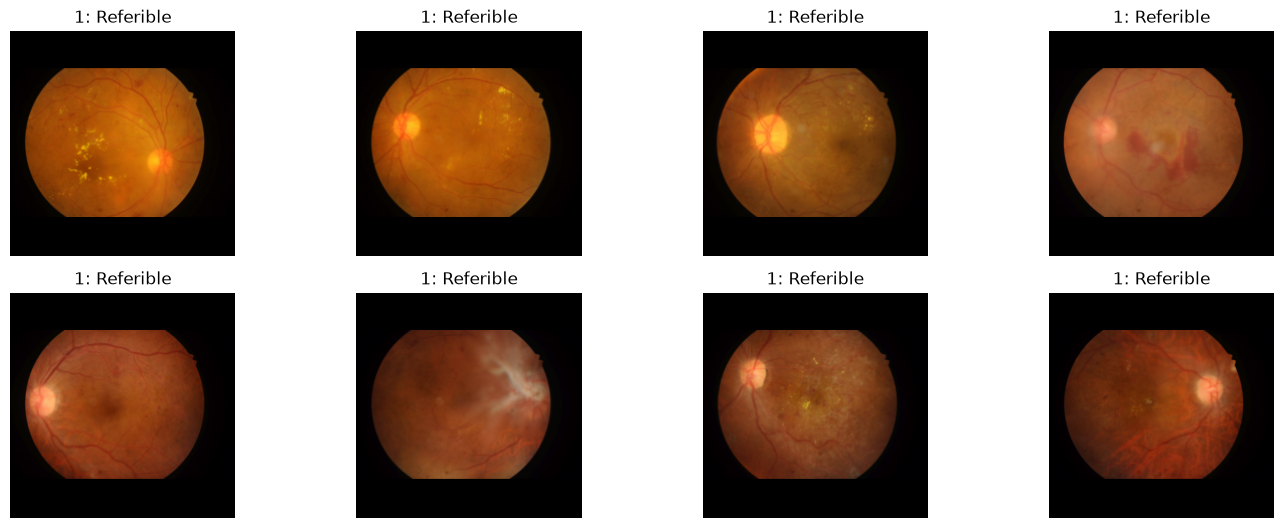

In [50]:
# Creamos un minidataset temporal sin caché ni mezcla para que la revisión sea instantánea
quick_check_ds = make_dataset(
    train_df.head(BATCH_SIZE),
    training=False,
    cache_name=None,
)

batch_images, batch_labels = next(
    iter(quick_check_ds.take(1))
)

print("Forma de las imágenes:", batch_images.shape)
print("Tipo de dato:", batch_images.dtype)
print("Forma de etiquetas:", batch_labels.shape)
print("Rango:", batch_images.numpy().min(), batch_images.numpy().max())

plt.figure(figsize=(14, 8))

images_to_show = min(12, len(batch_images))

for index in range(images_to_show):
    plt.subplot(3, 4, index + 1)

    plt.imshow(
        batch_images[index].numpy().astype(np.uint8)
    )

    label = int(batch_labels[index].numpy())

    plt.title(
        f"{label}: {CLASS_NAMES[label]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [51]:
# 9. CAPAS DE CAPSULENET

@tf.keras.utils.register_keras_serializable(package="ClinicalCapsNet")
def squash(vectors, axis=-1, epsilon=1e-7):
    vectors = tf.cast(vectors, tf.float32)
    squared_norm = tf.reduce_sum(
        tf.square(vectors),
        axis=axis,
        keepdims=True,
    )
    scale = (
        squared_norm
        / (1.0 + squared_norm)
        / tf.sqrt(squared_norm + epsilon)
    )
    return scale * vectors


@tf.keras.utils.register_keras_serializable(package="ClinicalCapsNet")
class SquashLayer(tf.keras.layers.Layer):
    def call(self, inputs):
        return squash(inputs)


@tf.keras.utils.register_keras_serializable(package="ClinicalCapsNet")
class CapsuleLayer(tf.keras.layers.Layer):
    def __init__(
        self,
        num_capsule,
        dim_capsule,
        routing_iterations=3,
        **kwargs,
    ):
        super().__init__(dtype="float32", **kwargs)
        self.num_capsule = int(num_capsule)
        self.dim_capsule = int(dim_capsule)
        self.routing_iterations = int(routing_iterations)

    def build(self, input_shape):
        input_num_capsule = input_shape[1]
        input_dim_capsule = input_shape[2]

        if input_num_capsule is None or input_dim_capsule is None:
            raise ValueError(
                "Las dimensiones de las cápsulas deben ser estáticas."
            )

        self.input_num_capsule = int(input_num_capsule)
        self.input_dim_capsule = int(input_dim_capsule)

        self.W = self.add_weight(
            name="transformation_matrix",
            shape=(
                self.input_num_capsule,
                self.num_capsule,
                self.dim_capsule,
                self.input_dim_capsule,
            ),
            initializer="glorot_uniform",
            trainable=True,
            dtype=tf.float32,
        )

        super().build(input_shape)

    def call(self, inputs):
        inputs = tf.cast(inputs, tf.float32)

        predictions = tf.einsum(
            "bni,njoi->bnjo",
            inputs,
            self.W,
        )

        routing_logits = tf.zeros(
            tf.shape(predictions)[:3],
            dtype=tf.float32,
        )

        outputs = None

        for iteration in range(self.routing_iterations):
            coupling = tf.nn.softmax(routing_logits, axis=-1)

            routed_predictions = (
                predictions
                if iteration == self.routing_iterations - 1
                else tf.stop_gradient(predictions)
            )

            preactivation = tf.einsum(
                "bnj,bnjo->bjo",
                coupling,
                routed_predictions,
            )
            outputs = squash(preactivation)

            if iteration < self.routing_iterations - 1:
                agreement = tf.einsum(
                    "bnjo,bjo->bnj",
                    tf.stop_gradient(predictions),
                    outputs,
                )
                routing_logits = routing_logits + agreement

        return outputs

    def get_config(self):
        config = super().get_config()
        config.update(
            {
                "num_capsule": self.num_capsule,
                "dim_capsule": self.dim_capsule,
                "routing_iterations": self.routing_iterations,
            }
        )
        return config


@tf.keras.utils.register_keras_serializable(package="ClinicalCapsNet")
class CapsuleLength(tf.keras.layers.Layer):
    def call(self, inputs):
        inputs = tf.cast(inputs, tf.float32)
        return tf.sqrt(
            tf.reduce_sum(tf.square(inputs), axis=-1) + 1e-7
        )

In [52]:
# 10. MARGIN LOSS Y MÉTRICAS

@tf.keras.utils.register_keras_serializable(package="ClinicalCapsNet")
class MarginLoss(tf.keras.losses.Loss):
    def __init__(
        self,
        m_plus=0.9,
        m_minus=0.1,
        absent_class_weight=0.5,
        name="margin_loss",
        **kwargs,
    ):
        super().__init__(name=name, **kwargs)
        self.m_plus = float(m_plus)
        self.m_minus = float(m_minus)
        self.absent_class_weight = float(absent_class_weight)

    def call(self, y_true, y_pred):
        y_true = tf.cast(y_true, tf.float32)
        y_pred = tf.cast(y_pred, tf.float32)

        positive = tf.square(
            tf.maximum(0.0, self.m_plus - y_pred)
        )
        negative = tf.square(
            tf.maximum(0.0, y_pred - self.m_minus)
        )

        loss = (
            y_true * positive
            + self.absent_class_weight
            * (1.0 - y_true)
            * negative
        )
        return tf.reduce_sum(loss, axis=-1)

    def get_config(self):
        config = super().get_config()
        config.update(
            {
                "m_plus": self.m_plus,
                "m_minus": self.m_minus,
                "absent_class_weight": self.absent_class_weight,
            }
        )
        return config


def positive_capsule_score(y_pred):
    y_pred = tf.cast(y_pred, tf.float32)
    return y_pred[:, 1] / (
        tf.reduce_sum(y_pred, axis=-1) + 1e-7
    )


@tf.keras.utils.register_keras_serializable(package="ClinicalCapsNet")
class CapsuleAUC(tf.keras.metrics.Metric):
    def __init__(self, curve="ROC", name="auc", **kwargs):
        super().__init__(name=name, **kwargs)
        self.curve = curve
        self.metric = tf.keras.metrics.AUC(curve=curve)

    def update_state(self, y_true, y_pred, sample_weight=None):
        labels = tf.cast(y_true[:, 1], tf.float32)
        scores = positive_capsule_score(y_pred)
        self.metric.update_state(
            labels,
            scores,
            sample_weight=sample_weight,
        )

    def result(self):
        return self.metric.result()

    def reset_state(self):
        self.metric.reset_state()

    def get_config(self):
        config = super().get_config()
        config.update({"curve": self.curve})
        return config


@tf.keras.utils.register_keras_serializable(package="ClinicalCapsNet")
class CapsuleBinaryAccuracy(tf.keras.metrics.Metric):
    def __init__(self, name="accuracy", **kwargs):
        super().__init__(name=name, **kwargs)
        self.metric = tf.keras.metrics.BinaryAccuracy(threshold=0.5)

    def update_state(self, y_true, y_pred, sample_weight=None):
        labels = tf.cast(y_true[:, 1], tf.float32)
        scores = positive_capsule_score(y_pred)
        self.metric.update_state(
            labels,
            scores,
            sample_weight=sample_weight,
        )

    def result(self):
        return self.metric.result()

    def reset_state(self):
        self.metric.reset_state()

In [54]:
# 11. CONSTRUIR Y COMPILAR EL MODELO

def conv_block(x, filters, kernel_size, strides, name):
    x = tf.keras.layers.Conv2D(
        filters,
        kernel_size,
        strides=strides,
        padding="same",
        use_bias=False,
        kernel_initializer="he_normal",
        name=f"{name}_conv",
    )(x)
    x = tf.keras.layers.BatchNormalization(
        name=f"{name}_bn"
    )(x)
    return tf.keras.layers.Activation(
        "swish",
        name=f"{name}_swish",
    )(x)


def build_clinical_capsnet(image_size, routing_iterations):
    inputs = tf.keras.Input(
        shape=(*image_size, 3),
        name="fundus_image",
    )

    x = conv_block(inputs, 32, 5, 2, "stem")
    x = conv_block(x, 64, 3, 2, "block1")
    x = conv_block(x, 96, 3, 2, "block2")
    x = conv_block(x, 128, 3, 2, "block3")

    # 3 capas intermedias añadidas para mejorar la extracción de características y precisión
    # Usamos strides=1 para mantener la resolución espacial intacta en este nivel
    x = conv_block(x, 128, 3, 1, "block4_extra")
    x = conv_block(x, 128, 3, 1, "block5_extra")
    x = conv_block(x, 128, 3, 1, "block6_extra")

    # Aumentamos el dropout espacial a 0.45 para mayor regularización
    x = tf.keras.layers.SpatialDropout2D(
        0.45,
        name="feature_dropout",
    )(x)

    primary_types = 8
    primary_dim = 8

    x = tf.keras.layers.Conv2D(
        primary_types * primary_dim,
        3,
        padding="same",
        use_bias=False,
        kernel_initializer="he_normal",
        name="primary_caps_conv",
    )(x)
    x = tf.keras.layers.BatchNormalization(
        name="primary_caps_bn"
    )(x)
    x = tf.keras.layers.Activation(
        "swish",
        name="primary_caps_activation",
    )(x)

    x = tf.keras.layers.Reshape(
        (-1, primary_dim),
        name="primary_caps_reshape",
    )(x)
    x = SquashLayer(name="primary_caps_squash")(x)

    x = CapsuleLayer(
        num_capsule=2,
        dim_capsule=16,
        routing_iterations=routing_iterations,
        name="diagnostic_capsules",
    )(x)

    outputs = CapsuleLength(
        name="capsule_lengths"
    )(x)

    return tf.keras.Model(
        inputs,
        outputs,
        name="ClinicalCapsuleNet",
    )


model = build_clinical_capsnet(
    IMG_SIZE,
    ROUTING_ITERATIONS,
)

optimizer = tf.keras.optimizers.AdamW(
    learning_rate=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    clipnorm=1.0,
)

model.compile(
    optimizer=optimizer,
    loss=MarginLoss(),
    metrics=[
        CapsuleBinaryAccuracy(name="accuracy"),
        CapsuleAUC(curve="ROC", name="auc"),
        CapsuleAUC(curve="PR", name="pr_auc"),
    ],
)

model.summary()


Model: "ClinicalCapsuleNet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ fundus_image (InputLayer)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ stem_conv (Conv2D)              │ (None, 112, 112, 32)   │         2,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ stem_bn (BatchNormalization)    │ (None, 112, 112, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ stem_swish (Activation)         │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv (Conv2D)            │ (None, 56, 56, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_bn (BatchNormalization)  │ (None, 56, 56, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_swish (Activation)       │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv (Conv2D)            │ (None, 28, 28, 96)     │        55,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_bn (BatchNormalization)  │ (None, 28, 28, 96)     │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_swish (Activation)       │ (None, 28, 28, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv (Conv2D)            │ (None, 14, 14, 128)    │       110,592 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_bn (BatchNormalization)  │ (None, 14, 14, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_swish (Activation)       │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_extra_conv (Conv2D)      │ (None, 14, 14, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_extra_bn                 │ (None, 14, 14, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_extra_swish (Activation) │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_extra_conv (Conv2D)      │ (None, 14, 14, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_extra_bn                 │ (None, 14, 14, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_extra_swish (Activation) │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block6_extra_conv (Conv2D)      │ (None, 14, 14, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block6_extra_bn                 │ (None, 14, 14, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block6_extra_swish (Activation) │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ feature_dropout                 │ (None, 14, 14, 128)    │             0 │
│ (SpatialDropout2D)              │                        │             

 Total params: 1,107,296 (4.22 MB)

 Trainable params: 1,105,760 (4.22 MB)

 Non-trainable params: 1,536 (6.00 KB)

In [55]:
if 'model' in locals():
    print("Capas en el modelo principal:", len(model.layers))
    for layer in model.layers:
        if isinstance(layer, keras.Model):
            print(f"Capas dentro del submodelo '{layer.name}':", len(layer.layers))
else:
    print("El modelo no está definido. Por favor, ejecuta las celdas anteriores primero.")

Capas en el modelo principal: 30


In [57]:

def create_callbacks(
    phase_name,
    checkpoint_path,
    patience=4,
):
    phase_log_path = LOG_DIR / (
        f"{phase_name}_training_log.csv"
    )

    backup_path = RUN_DIR / (
        f"backup_{phase_name}"
    )

    return [
        keras.callbacks.ModelCheckpoint(
            filepath=str(checkpoint_path),
            monitor="val_auc_pr",
            mode="max",
            save_best_only=True,
            save_weights_only=False,
            verbose=1,
        ),

        keras.callbacks.EarlyStopping(
            monitor="val_auc_pr",
            mode="max",
            patience=patience,
            restore_best_weights=True,
            verbose=1,
        ),

        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            mode="min",
            factor=0.3,
            patience=2,
            min_lr=1e-7,
            verbose=1,
        ),

        keras.callbacks.CSVLogger(
            filename=str(phase_log_path),
            append=False,
        ),

        keras.callbacks.BackupAndRestore(
            backup_dir=str(backup_path),
        ),

        keras.callbacks.TerminateOnNaN(),
    ]

In [58]:

# ============================================================
# 13. CALLBACKS Y ENTRENAMIENTO CAPSULENET
# ============================================================

import tensorflow as tf

# ============================================================
# 1. CORREGIR FORMATO DE ETIQUETAS TRAIN
# ============================================================

def convert_to_one_hot(images, labels):

    labels = tf.cast(labels, tf.int32)

    labels = tf.one_hot(
        labels,
        depth=2,
        dtype=tf.float32
    )

    return images, labels


# Convertir solamente si las etiquetas son (batch,)
label_shape = train_ds.element_spec[1].shape

if label_shape.rank == 1:

    train_ds = train_ds.map(
        convert_to_one_hot,
        num_parallel_calls=tf.data.AUTOTUNE
    )

elif label_shape.rank != 2 or label_shape[-1] != 2:
    raise ValueError(
        f"Formato de etiquetas no esperado: {label_shape}"
    )

print("TRAIN:", train_ds.element_spec[1].shape)
print("VALIDACION:", val_monitor_ds.element_spec[1].shape)


# ============================================================
# 2. CALLBACKS
# ============================================================

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        str(BEST_MODEL_PATH),
        monitor="val_auc",
        mode="max",
        save_best_only=True,
        verbose=1,
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_auc",
        mode="max",
        patience=8,
        min_delta=1e-4,
        restore_best_weights=True,
        verbose=1,
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.35,
        patience=3,
        min_lr=1e-6,
        verbose=1,
    ),

    tf.keras.callbacks.CSVLogger(
        str(HISTORY_CSV_PATH)
    ),

    tf.keras.callbacks.TerminateOnNaN(),
]


# ============================================================
# 3. ENTRENAMIENTO
# ============================================================

history= model.fit(
    train_ds,
    validation_data=val_monitor_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1,
)


# ============================================================
# 4. GUARDAR MODELO
# ============================================================

model.save(FINAL_MODEL_PATH)

print("Mejor modelo:", BEST_MODEL_PATH)
print("Modelo final:", FINAL_MODEL_PATH)


TRAIN: (None, 2)
VALIDACION: (None, 2)
Epoch 1/40


289/289 ━━━━━━━━━━━━━━━━━━━━ 0s 192ms/step - accuracy: 0.6797 - auc: 0.7333 - loss: 0.1986 - pr_auc: 0.8104
Epoch 1: val_auc improved from None to 0.85732, saving model to \data\modelos\CapsuleNet\capsulenet_best_auc.keras

Epoch 1: finished saving model to \data\modelos\CapsuleNet\capsulenet_best_auc.keras
289/289 ━━━━━━━━━━━━━━━━━━━━ 70s 202ms/step - accuracy: 0.6797 - auc: 0.7333 - loss: 0.1986 - pr_auc: 0.8104 - val_accuracy: 0.3735 - val_auc: 0.8573 - val_loss: 0.2559 - val_pr_auc: 0.9245 - learning_rate: 1.0000e-04
Epoch 2/40
289/289 ━━━━━━━━━━━━━━━━━━━━ 0s 195ms/step - accuracy: 0.6818 - auc: 0.7533 - loss: 0.1792 - pr_auc: 0.8279
Epoch 2: val_auc did not improve from 0.85732
289/289 ━━━━━━━━━━━━━━━━━━━━ 57s 198ms/step - accuracy: 0.6818 - auc: 0.7533 - loss: 0.1792 - pr_auc: 0.8279 - val_accuracy: 0.7831 - val_auc: 0.8505 - val_loss: 0.1481 - val_pr_auc: 0.9171 - learning_rate: 1.0000e-04
Epoch 3/40
289/289 ━━━━━━━━━━━━━━━━━━━━ 0s 193ms/step - accuracy: 0.7022 - auc: 0.7790 - l

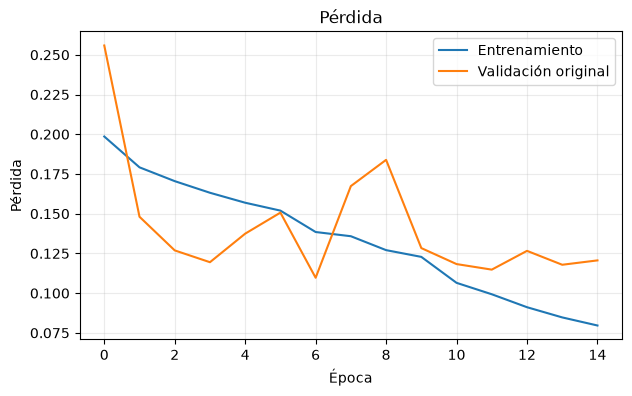

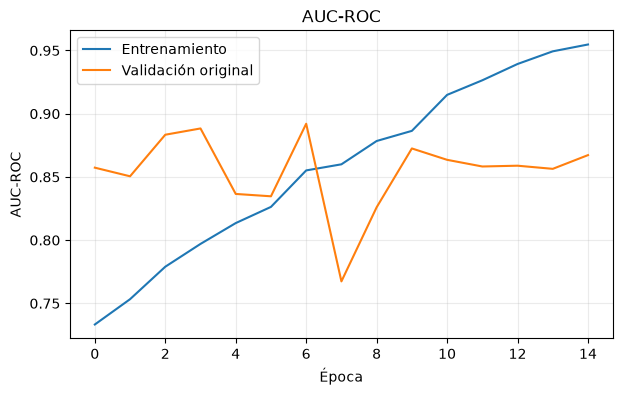

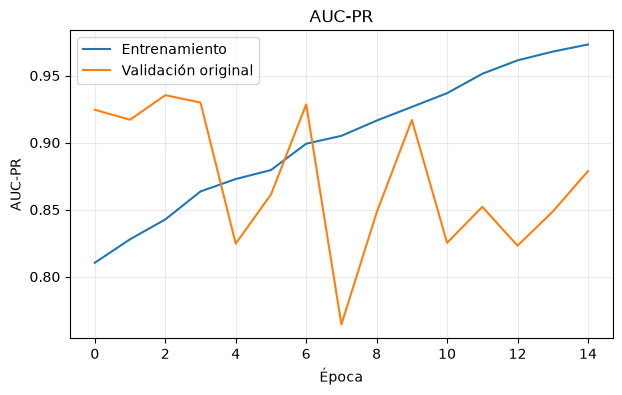

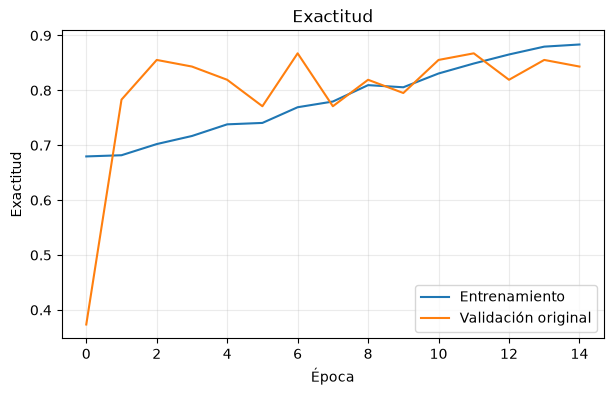

In [59]:
# 14. CURVAS DE ENTRENAMIENTO

def plot_history(history_object):
    pairs = [
        ("loss", "val_loss", "Pérdida"),
        ("auc", "val_auc", "AUC-ROC"),
        ("pr_auc", "val_pr_auc", "AUC-PR"),
        ("accuracy", "val_accuracy", "Exactitud"),
    ]

    for train_key, val_key, title in pairs:
        if train_key not in history_object.history:
            continue

        plt.figure(figsize=(7, 4))
        plt.plot(
            history_object.history[train_key],
            label="Entrenamiento",
        )
        if val_key in history_object.history:
            plt.plot(
                history_object.history[val_key],
                label="Validación original",
            )
        plt.title(title)
        plt.xlabel("Época")
        plt.ylabel(title)
        plt.legend()
        plt.grid(alpha=0.25)
        plt.show()

plot_history(history)

In [61]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
)

In [62]:
# 15. EVALUACIÓN POR PACIENTE

# Reconstruimos la arquitectura del modelo para evitar el error de deserialización
best_model = build_clinical_capsnet(IMG_SIZE, ROUTING_ITERATIONS)
# Cargamos únicamente los pesos guardados de la mejor época
best_model.load_weights(BEST_MODEL_PATH)

capsule_lengths = best_model.predict(
    make_prediction_dataset(val_df),
    verbose=1,
)

view_probability = capsule_lengths[:, 1] / (
    capsule_lengths.sum(axis=1) + 1e-7
)

val_results = val_df[
    ["Image name", "patient_id", "binary_label", "image_path"]
].copy()
val_results["probability"] = view_probability

label_consistency = (
    val_results.groupby("patient_id")["binary_label"].nunique()
)
if (label_consistency > 1).any():
    raise ValueError("Hay etiquetas contradictorias por paciente.")

patient_results = (
    val_results.groupby("patient_id", as_index=False)
    .agg(
        binary_label=("binary_label", "first"),
        probability_mean=("probability", "mean"),
        probability_median=("probability", "median"),
        probability_max=("probability", "max"),
        n_views=("probability", "size"),
    )
)

y_patient = patient_results["binary_label"].to_numpy()
p_patient = patient_results["probability_mean"].to_numpy()

for column in [
    "probability_mean",
    "probability_median",
    "probability_max",
]:
    probability = patient_results[column].to_numpy()
    print(
        column,
        "| ROC-AUC:",
        round(roc_auc_score(y_patient, probability), 4),
        "| PR-AUC:",
        round(average_precision_score(y_patient, probability), 4),
        "| Brier:",
        round(brier_score_loss(y_patient, probability), 4),
    )


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 84ms/step
probability_mean | ROC-AUC: 0.8921 | PR-AUC: 0.9294 | Brier: 0.13
probability_median | ROC-AUC: 0.8921 | PR-AUC: 0.9294 | Brier: 0.13
probability_max | ROC-AUC: 0.8921 | PR-AUC: 0.9294 | Brier: 0.13


In [63]:
# 16. SELECCIONAR UMBRALES CLÍNICOS

def youden_threshold(y_true, probability):
    fpr, tpr, thresholds = roc_curve(y_true, probability)
    valid = np.isfinite(thresholds)
    fpr = fpr[valid]
    tpr = tpr[valid]
    thresholds = thresholds[valid]
    return float(thresholds[np.argmax(tpr - fpr)])


def threshold_for_sensitivity(
    y_true,
    probability,
    target=0.90,
):
    fpr, tpr, thresholds = roc_curve(y_true, probability)
    valid = np.isfinite(thresholds)
    fpr = fpr[valid]
    tpr = tpr[valid]
    thresholds = thresholds[valid]

    candidates = np.where(tpr >= target)[0]
    if len(candidates) == 0:
        return float(np.min(probability))

    best = candidates[np.argmin(fpr[candidates])]
    return float(thresholds[best])


thresholds = {
    "youden": youden_threshold(y_patient, p_patient),
    "sensitivity_90": threshold_for_sensitivity(
        y_patient,
        p_patient,
        0.90,
    ),
    "sensitivity_95": threshold_for_sensitivity(
        y_patient,
        p_patient,
        0.95,
    ),
}

with open(THRESHOLD_PATH, "w", encoding="utf-8") as file:
    json.dump(thresholds, file, indent=2)

print(json.dumps(thresholds, indent=2))

{
  "youden": 0.4272204339504242,
  "sensitivity_90": 0.4272204339504242,
  "sensitivity_95": 0.3175915479660034
}


In [67]:

# ============================================================
# CONSULTAR UMBRALES CAPSULENET
# ============================================================

print("===== UMBRALES CALCULADOS =====")

for name, value in thresholds.items():
    print(f"{name}: {value:.4f}")

print("\n===== UMBRAL SELECCIONADO =====")

print(f"Umbral utilizado: {SELECTED_THRESHOLD:.4f}")


===== UMBRALES CALCULADOS =====
youden: 0.4272
sensitivity_90: 0.4272
sensitivity_95: 0.3176

===== UMBRAL SELECCIONADO =====
Umbral utilizado: 0.4272


In [68]:

for name, threshold in thresholds.items():

    results = clinical_metrics(
        y_patient,
        p_patient,
        threshold
    )

    print(f"\nEstrategia: {name}")
    print(f"Umbral: {threshold:.4f}")
    print(f"Sensibilidad: {results['sensitivity']:.2%}")
    print(f"Especificidad: {results['specificity']:.2%}")
    print(f"Falsos negativos: {results['fn']}")
    print(f"Falsos positivos: {results['fp']}")



Estrategia: youden
Umbral: 0.4272
Sensibilidad: 92.31%
Especificidad: 80.65%
Falsos negativos: 4
Falsos positivos: 6

Estrategia: sensitivity_90
Umbral: 0.4272
Sensibilidad: 92.31%
Especificidad: 80.65%
Falsos negativos: 4
Falsos positivos: 6

Estrategia: sensitivity_95
Umbral: 0.3176
Sensibilidad: 98.08%
Especificidad: 54.84%
Falsos negativos: 1
Falsos positivos: 14


In [69]:

# ============================================================
# IMPORTACIONES PARA METRICAS CLINICAS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    matthews_corrcoef,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    classification_report,
)

print("Importaciones realizadas correctamente.")


Importaciones realizadas correctamente.


,strategy,threshold,accuracy,balanced_accuracy,sensitivity,specificity,precision_ppv,npv,f1,mcc,roc_auc,pr_auc,brier,tn,fp,fn,tp
0,youden,0.4272,0.8795,0.8648,0.9231,0.8065,0.8889,0.8621,0.9057,0.7402,0.8921,0.9294,0.13,25,6,4,48
1,sensitivity_90,0.4272,0.8795,0.8648,0.9231,0.8065,0.8889,0.8621,0.9057,0.7402,0.8921,0.9294,0.13,25,6,4,48
2,sensitivity_95,0.3176,0.8193,0.7646,0.9808,0.5484,0.7846,0.9444,0.8718,0.6211,0.8921,0.9294,0.13,17,14,1,51


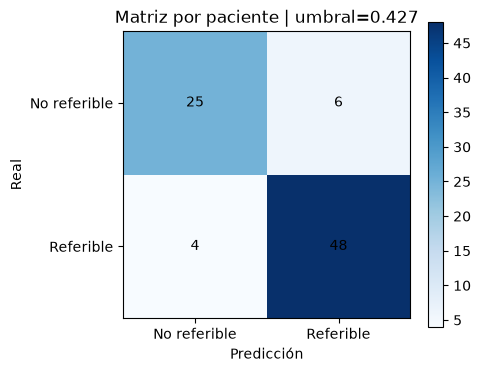

              precision    recall  f1-score   support

No referible     0.8621    0.8065    0.8333        31
   Referible     0.8889    0.9231    0.9057        52

    accuracy                         0.8795        83
   macro avg     0.8755    0.8648    0.8695        83
weighted avg     0.8789    0.8795    0.8786        83



In [70]:
# 17. MÉTRICAS CLÍNICAS Y MATRIZ DE CONFUSIÓN

def clinical_metrics(y_true, probability, threshold):
    prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_true,
        prediction,
        labels=[0, 1],
    ).ravel()

    sensitivity = tp / (tp + fn) if tp + fn else np.nan
    specificity = tn / (tn + fp) if tn + fp else np.nan
    ppv = tp / (tp + fp) if tp + fp else np.nan
    npv = tn / (tn + fn) if tn + fn else np.nan

    return {
        "threshold": threshold,
        "accuracy": accuracy_score(y_true, prediction),
        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            prediction,
        ),
        "sensitivity": sensitivity,
        "specificity": specificity,
        "precision_ppv": ppv,
        "npv": npv,
        "f1": f1_score(y_true, prediction, zero_division=0),
        "mcc": matthews_corrcoef(y_true, prediction),
        "roc_auc": roc_auc_score(y_true, probability),
        "pr_auc": average_precision_score(y_true, probability),
        "brier": brier_score_loss(y_true, probability),
        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp,
    }


metrics_table = pd.DataFrame(
    [
        {
            "strategy": name,
            **clinical_metrics(
                y_patient,
                p_patient,
                threshold,
            ),
        }
        for name, threshold in thresholds.items()
    ]
)

display(metrics_table.round(4))
metrics_table.to_csv(
    OUTPUT_DIR / "capsulenet_clinical_metrics.csv",
    index=False,
)

SELECTED_THRESHOLD = thresholds["sensitivity_90"]
y_pred = (p_patient >= SELECTED_THRESHOLD).astype(int)
cm = confusion_matrix(y_patient, y_pred, labels=[0, 1])

plt.figure(figsize=(5, 4))
plt.imshow(cm, cmap="Blues")
plt.xticks([0, 1], ["No referible", "Referible"])
plt.yticks([0, 1], ["No referible", "Referible"])
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title(
    f"Matriz por paciente | umbral={SELECTED_THRESHOLD:.3f}"
)

for row in range(2):
    for col in range(2):
        plt.text(col, row, cm[row, col], ha="center", va="center")

plt.colorbar()
plt.tight_layout()
plt.show()

print(
    classification_report(
        y_patient,
        y_pred,
        target_names=["No referible", "Referible"],
        digits=4,
        zero_division=0,
    )
)

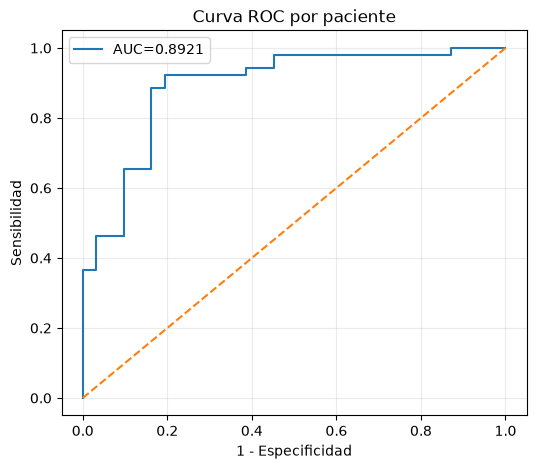

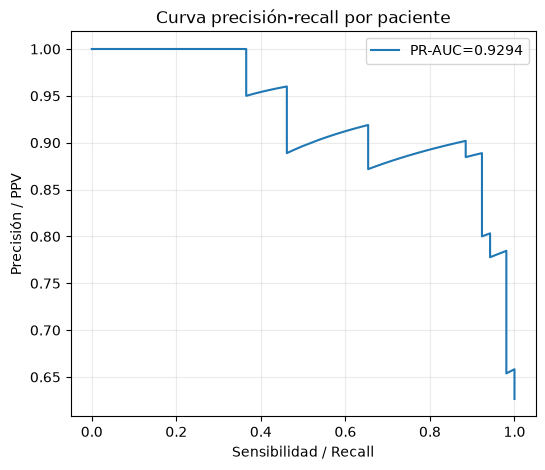

In [71]:
# 18. CURVAS ROC Y PRECISIÓN-RECALL

fpr, tpr, _ = roc_curve(y_patient, p_patient)
roc_auc = roc_auc_score(y_patient, p_patient)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"AUC={roc_auc:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("1 - Especificidad")
plt.ylabel("Sensibilidad")
plt.title("Curva ROC por paciente")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

precision, recall, _ = precision_recall_curve(
    y_patient,
    p_patient,
)
pr_auc = average_precision_score(y_patient, p_patient)

plt.figure(figsize=(6, 5))
plt.plot(recall, precision, label=f"PR-AUC={pr_auc:.4f}")
plt.xlabel("Sensibilidad / Recall")
plt.ylabel("Precisión / PPV")
plt.title("Curva precisión-recall por paciente")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

In [72]:
# 19. GRAD-CAM ADAPTADO A LA CÁPSULA POSITIVA

def capsule_gradcam(
    model,
    image_batch,
    conv_layer_name="primary_caps_conv",
    class_index=1,
):
    grad_model = tf.keras.Model(
        model.inputs,
        [
            model.get_layer(conv_layer_name).output,
            model.output,
        ],
    )

    with tf.GradientTape() as tape:
        conv_output, lengths = grad_model(
            image_batch,
            training=False,
        )
        score = lengths[:, class_index] / (
            tf.reduce_sum(lengths, axis=-1) + 1e-7
        )

    gradients = tape.gradient(score, conv_output)
    weights = tf.reduce_mean(gradients, axis=(1, 2))
    heatmap = tf.reduce_sum(
        conv_output * weights[:, None, None, :],
        axis=-1,
    )
    heatmap = tf.nn.relu(heatmap)

    minimum = tf.reduce_min(heatmap, axis=(1, 2), keepdims=True)
    maximum = tf.reduce_max(heatmap, axis=(1, 2), keepdims=True)
    heatmap = (heatmap - minimum) / (
        maximum - minimum + 1e-7
    )

    return heatmap, score


def show_capsule_gradcam(
    model,
    image_path,
    true_label=None,
    threshold=0.5,
):
    image = decode_and_preprocess(tf.constant(str(image_path)))
    batch = image[None, ...]

    heatmap, score = capsule_gradcam(model, batch)
    heatmap = tf.image.resize(
        heatmap[..., None],
        [IMG_SIZE, IMG_SIZE],
    )[0, ..., 0].numpy()

    probability = float(score[0].numpy())
    prediction = int(probability >= threshold)

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(image)
    plt.title("Imagen preprocesada")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(image)
    plt.imshow(heatmap, cmap="jet", alpha=0.40)
    title = (
        f"P(referible)={probability:.3f} | "
        f"Pred={prediction}"
    )
    if true_label is not None:
        title += f" | Real={int(true_label)}"
    plt.title(title)
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    return {
        "probability": probability,
        "prediction": prediction,
        "true_label": true_label,
    }

In [86]:

# ============================================================
# IDENTIFICAR FUNCION GRAD-CAM CAPSULENET
# ============================================================

import inspect

print("===== FIRMA DE CAPSULE_GRADCAM =====")
print(inspect.signature(capsule_gradcam))

print("\n===== CODIGO DE CAPSULE_GRADCAM =====")

try:
    print(inspect.getsource(capsule_gradcam))
except (OSError, TypeError):
    print(
        "No se pudo recuperar automaticamente el codigo. "
        "Busca 'def capsule_gradcam' en el notebook."
    )


===== FIRMA DE CAPSULE_GRADCAM =====
(model, image_batch, conv_layer_name='primary_caps_conv', class_index=1)

===== CODIGO DE CAPSULE_GRADCAM =====
def capsule_gradcam(
    model,
    image_batch,
    conv_layer_name="primary_caps_conv",
    class_index=1,
):
    grad_model = tf.keras.Model(
        model.inputs,
        [
            model.get_layer(conv_layer_name).output,
            model.output,
        ],
    )

    with tf.GradientTape() as tape:
        conv_output, lengths = grad_model(
            image_batch,
            training=False,
        )
        score = lengths[:, class_index] / (
            tf.reduce_sum(lengths, axis=-1) + 1e-7
        )

    gradients = tape.gradient(score, conv_output)
    weights = tf.reduce_mean(gradients, axis=(1, 2))
    heatmap = tf.reduce_sum(
        conv_output * weights[:, None, None, :],
        axis=-1,
    )
    heatmap = tf.nn.relu(heatmap)

    minimum = tf.reduce_min(heatmap, axis=(1, 2), keepdims=True)
    maximum = tf.reduce_m

Capa analizada: primary_caps_conv
Salida convolucional: (None, 14, 14, 64)
Salida CapsuleNet: (None, 2)

===== CLASE 0 =====
Score capsula: 0.8249595165252686
Gradiente absoluto maximo: 0.0012606350937858224
Gradientes no nulos: 12544
CAM minimo: -0.0002944201696664095
CAM maximo: 0.0008169630309566855

Paciente: IDRiD_148
Imagen: IDRiD_148.jpg
Tipo: NO REFERIBLE (TN)

===== CLASE 1 =====
Score capsula: 0.8886321187019348
Gradiente absoluto maximo: 0.0004691566282417625
Gradientes no nulos: 12544
CAM minimo: -0.000626915309112519
CAM maximo: 0.0001943069655681029

Paciente: IDRiD_003
Imagen: IDRiD_003.jpg
Tipo: REFERIBLE (TP)


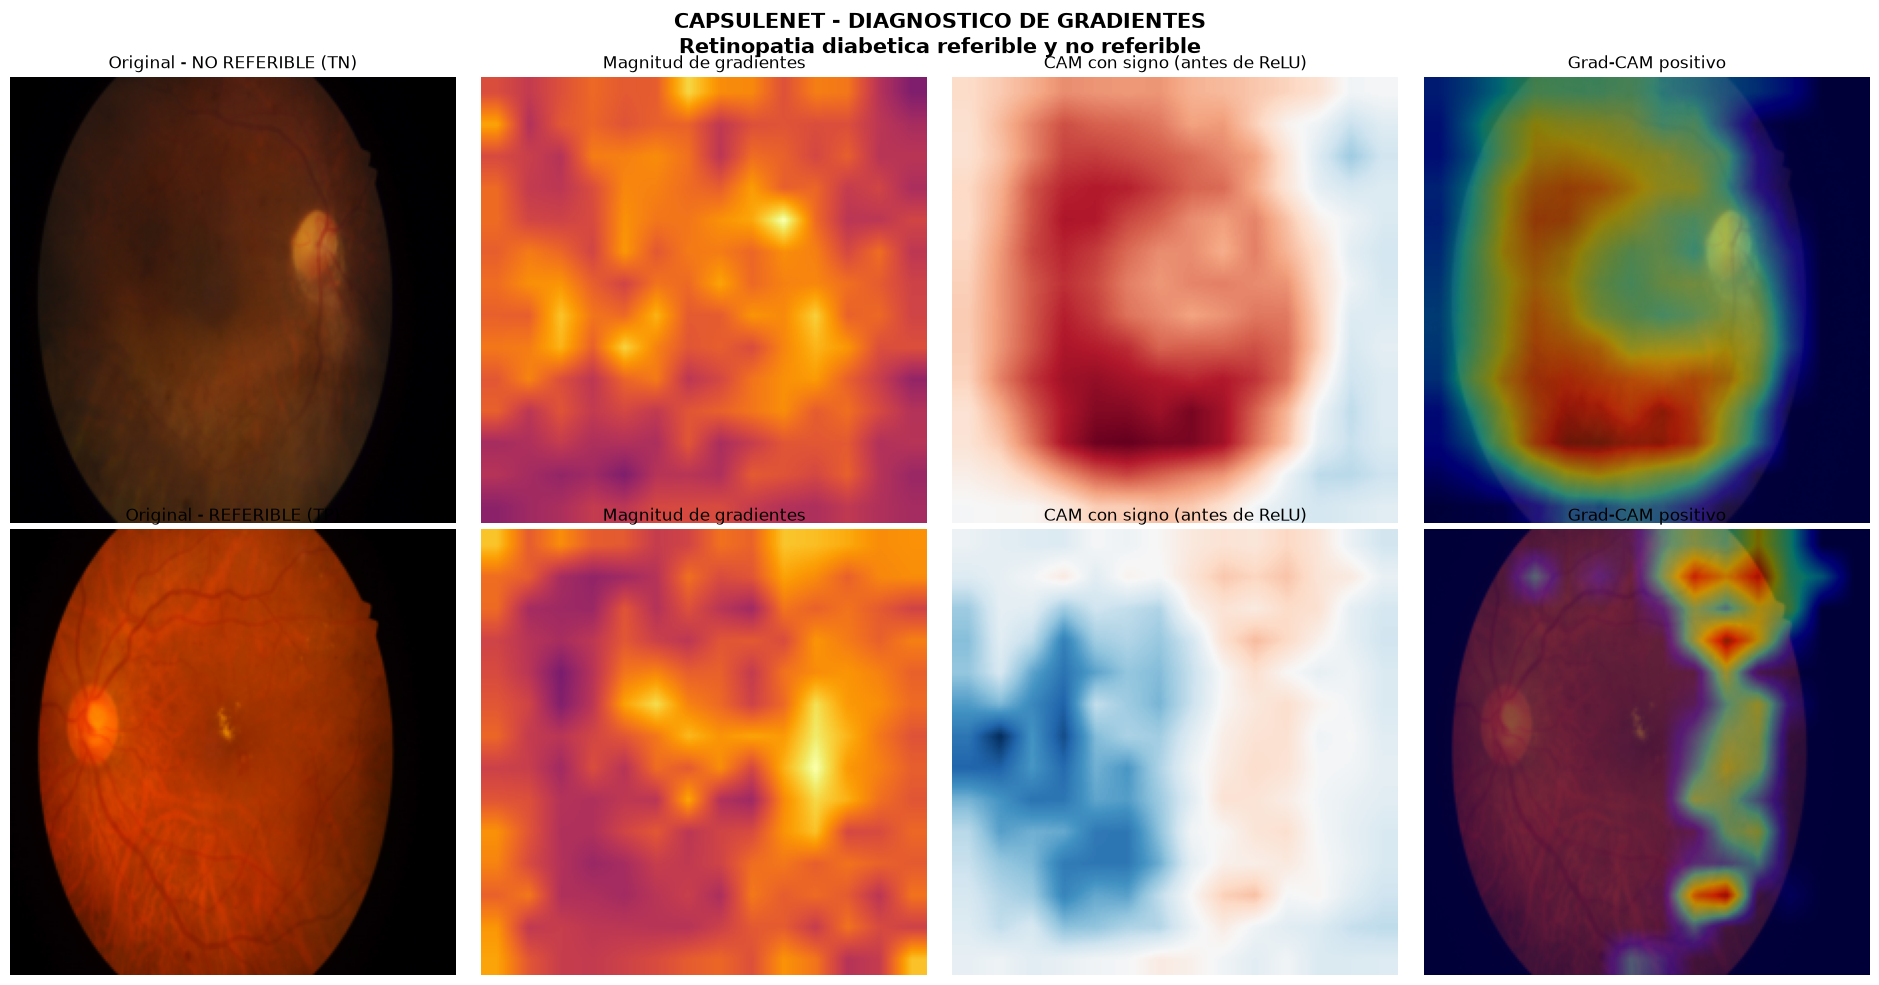

In [89]:

# ============================================================
# GRAD-CAM CAPSULENET - DIAGNOSTICO DE GRADIENTES
# CLASE 0: NO REFERIBLE
# CLASE 1: REFERIBLE
# ============================================================

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

CONV_LAYER = "primary_caps_conv"

# ============================================================
# 1. CONSTRUIR MODELO PARA GRADIENTES
# ============================================================

conv_layer = best_model.get_layer(CONV_LAYER)

grad_model = tf.keras.Model(
    inputs=best_model.inputs,
    outputs=[
        conv_layer.output,
        best_model.output
    ]
)

print("Capa analizada:", conv_layer.name)
print("Salida convolucional:", conv_layer.output.shape)
print("Salida CapsuleNet:", best_model.output_shape)


# ============================================================
# 2. CALCULAR GRADIENTES REALES
# ============================================================

def capsule_gradcam_diagnostic(
    image_batch,
    class_index
):

    with tf.GradientTape() as tape:

        conv_outputs, capsule_lengths = grad_model(
            image_batch,
            training=False
        )

        # Longitud de la capsula correspondiente
        class_score = tf.reduce_sum(
            capsule_lengths[:, class_index]
        )

    gradients = tape.gradient(
        class_score,
        conv_outputs
    )

    if gradients is None:
        raise RuntimeError(
            "No existen gradientes entre la capa "
            "convolucional y la salida de CapsuleNet."
        )

    gradients = tf.cast(gradients, tf.float32)
    conv_outputs = tf.cast(conv_outputs, tf.float32)

    tf.debugging.assert_all_finite(
        gradients,
        "Los gradientes contienen NaN o Inf."
    )

    # Magnitud real del gradiente por posicion
    gradient_magnitude = tf.reduce_mean(
        tf.abs(gradients),
        axis=-1
    )[0]

    # Pesos Grad-CAM por canal
    weights = tf.reduce_mean(
        gradients,
        axis=(1, 2),
        keepdims=True
    )

    # Mapa antes de ReLU: conserva valores negativos
    signed_cam = tf.reduce_sum(
        conv_outputs * weights,
        axis=-1
    )[0]

    # Grad-CAM estandar: contribuciones positivas
    positive_cam = tf.nn.relu(signed_cam)

    print(f"\n===== CLASE {class_index} =====")
    print("Score capsula:", float(class_score.numpy()))
    print(
        "Gradiente absoluto maximo:",
        float(tf.reduce_max(tf.abs(gradients)).numpy())
    )
    print(
        "Gradientes no nulos:",
        int(tf.math.count_nonzero(gradients).numpy())
    )
    print(
        "CAM minimo:",
        float(tf.reduce_min(signed_cam).numpy())
    )
    print(
        "CAM maximo:",
        float(tf.reduce_max(signed_cam).numpy())
    )

    return (
        gradient_magnitude.numpy(),
        signed_cam.numpy(),
        positive_cam.numpy()
    )


# ============================================================
# 3. FUNCIONES PARA VISUALIZACION
# ============================================================

def resize_map(heatmap):

    heatmap = tf.convert_to_tensor(
        heatmap,
        dtype=tf.float32
    )

    return tf.image.resize(
        heatmap[None, ..., None],
        size=IMG_SIZE,
        method="bilinear"
    )[0, :, :, 0].numpy()


def normalize_positive(array):

    array = np.asarray(array, dtype=np.float32)
    maximum = np.max(array)

    if maximum <= 0:
        return np.zeros_like(array)

    return array / maximum


def normalize_signed(array):

    array = np.asarray(array, dtype=np.float32)
    maximum = np.max(np.abs(array))

    if maximum <= 0:
        return np.zeros_like(array)

    return array / maximum


# ============================================================
# 4. SELECCIONAR PACIENTES TN Y TP
# ============================================================

patients = patient_results.copy()
views = val_results.copy()

patients["patient_id"] = patients["patient_id"].astype(str)
views["patient_id"] = views["patient_id"].astype(str)

patients["predicted_label"] = (
    patients["probability_mean"] >= SELECTED_THRESHOLD
).astype(int)

selected_cases = []

for target_class in [0, 1]:

    candidates = patients[
        (patients["binary_label"] == target_class)
        &
        (patients["predicted_label"] == target_class)
    ]

    if candidates.empty:
        raise ValueError(
            f"No hay pacientes correctamente "
            f"clasificados para clase {target_class}."
        )

    patient = candidates.iloc[0]

    patient_views = views[
        views["patient_id"] == patient["patient_id"]
    ]

    if patient_views.empty:
        raise ValueError(
            "No se encontraron imagenes del paciente."
        )

    selected_cases.append(
        (target_class, patient, patient_views.iloc[0])
    )


# ============================================================
# 5. GENERAR FIGURAS
# ============================================================

fig, axes = plt.subplots(
    2,
    4,
    figsize=(19, 10)
)

class_names = {
    0: "NO REFERIBLE (TN)",
    1: "REFERIBLE (TP)"
}

for row, (target_class, patient, case) in enumerate(
    selected_cases
):

    image_path = str(case["image_path"])

    image = decode_and_preprocess(
        tf.constant(image_path)
    )

    image = tf.cast(image, tf.float32)
    batch = image[None, ...]

    # Obtener los tres mapas
    gradient_map, signed_map, gradcam_map = (
        capsule_gradcam_diagnostic(
            batch,
            class_index=target_class
        )
    )

    # Redimensionar
    gradient_map = resize_map(gradient_map)
    signed_map = resize_map(signed_map)
    gradcam_map = resize_map(gradcam_map)

    # Normalizar individualmente
    gradient_display = normalize_positive(gradient_map)
    signed_display = normalize_signed(signed_map)
    gradcam_display = normalize_positive(gradcam_map)

    # Preparar imagen
    image_display = image.numpy().astype(np.float32)

    if image_display.min() < 0:
        if image_display.min() >= -1 and image_display.max() <= 1:
            image_display = (image_display + 1) / 2
        else:
            image_display = (
                image_display - image_display.min()
            ) / (
                np.ptp(image_display) + 1e-8
            )
    elif image_display.max() > 1:
        image_display = image_display / 255.0

    image_display = np.clip(image_display, 0, 1)

    # Imagen
    axes[row, 0].imshow(image_display)
    axes[row, 0].set_title(
        f"Original - {class_names[target_class]}"
    )

    # Magnitud del gradiente real
    axes[row, 1].imshow(
        gradient_display,
        cmap="inferno",
        vmin=0,
        vmax=1
    )
    axes[row, 1].set_title(
        "Magnitud de gradientes"
    )

    # CAM con valores positivos y negativos
    axes[row, 2].imshow(
        signed_display,
        cmap="RdBu_r",
        vmin=-1,
        vmax=1
    )
    axes[row, 2].set_title(
        "CAM con signo (antes de ReLU)"
    )

    # Grad-CAM convencional
    axes[row, 3].imshow(image_display)

    if np.max(gradcam_map) > 0:

        axes[row, 3].imshow(
            gradcam_display,
            cmap="jet",
            alpha=0.45,
            vmin=0,
            vmax=1
        )

    else:

        axes[row, 3].text(
            0.5,
            0.5,
            "SIN CONTRIBUCIONES\nPOSITIVAS",
            transform=axes[row, 3].transAxes,
            ha="center",
            va="center",
            fontsize=12,
            color="white",
            bbox=dict(
                facecolor="black",
                alpha=0.75
            )
        )

    axes[row, 3].set_title(
        "Grad-CAM positivo"
    )

    for ax in axes[row]:
        ax.axis("off")

    print("\nPaciente:", patient["patient_id"])
    print("Imagen:", Path(image_path).name)
    print("Tipo:", class_names[target_class])


plt.suptitle(
    "CAPSULENET - DIAGNOSTICO DE GRADIENTES\n"
    "Retinopatia diabetica referible y no referible",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


In [90]:

# ============================================================
# AUDITORIA DE ACTIVACIONES DENTRO Y FUERA DE LA RETINA
# ============================================================

# Mascara aproximada del campo retinal
retina_mask = (
    np.max(image_display, axis=2) > 0.10
)

# Activaciones positivas
cam_positive = np.maximum(
    gradcam_map,
    0.0
)

total_activation = np.sum(cam_positive)

inside_activation = np.sum(
    cam_positive[retina_mask]
)

outside_activation = np.sum(
    cam_positive[~retina_mask]
)

if total_activation > 1e-8:

    inside_percentage = (
        100 * inside_activation / total_activation
    )

    outside_percentage = (
        100 * outside_activation / total_activation
    )

else:
    inside_percentage = np.nan
    outside_percentage = np.nan

print("\n===== AUDITORIA GRAD-CAM =====")
print("Paciente:", patient["patient_id"])
print("Clase:", target_class)

print(
    f"Activacion dentro de retina: "
    f"{inside_percentage:.2f}%"
)

print(
    f"Activacion fuera de retina: "
    f"{outside_percentage:.2f}%"
)



===== AUDITORIA GRAD-CAM =====
Paciente: IDRiD_003
Clase: 1
Activacion dentro de retina: 87.37%
Activacion fuera de retina: 12.63%



===== ANALISIS DE CONCENTRACION =====
Area retinal: 69.40%
Activacion dentro: 87.37%
Concentracion relativa: 1.259


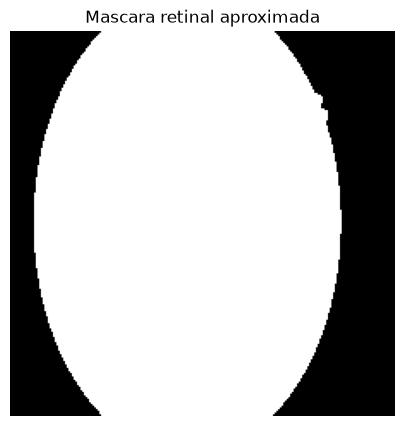

In [91]:

# ============================================================
# EVALUACION DE CONCENTRACION GRAD-CAM
# ============================================================

# Porcentaje del area que ocupa la retina
retina_area = np.mean(retina_mask) * 100

# Porcentaje de activacion dentro de la retina
total = np.sum(cam_positive)

if total > 1e-8:

    activation_inside = (
        np.sum(cam_positive[retina_mask])
        / total
    ) * 100

    # Concentracion relativa respecto al area
    concentration_ratio = (
        activation_inside / retina_area
        if retina_area > 0 else np.nan
    )

else:
    activation_inside = np.nan
    concentration_ratio = np.nan

print("\n===== ANALISIS DE CONCENTRACION =====")

print(f"Area retinal: {retina_area:.2f}%")

print(
    f"Activacion dentro: "
    f"{activation_inside:.2f}%"
)

print(
    f"Concentracion relativa: "
    f"{concentration_ratio:.3f}"
)

# Comprobar visualmente la mascara retinal
plt.figure(figsize=(5, 5))
plt.imshow(retina_mask, cmap="gray")
plt.title("Mascara retinal aproximada")
plt.axis("off")
plt.show()


===== DISTRIBUCION GRAD-CAM RETINAL =====
Area del borde: 13.86%
Area interior: 86.14%
Activacion en borde: 10.27%
Activacion interior: 89.73%


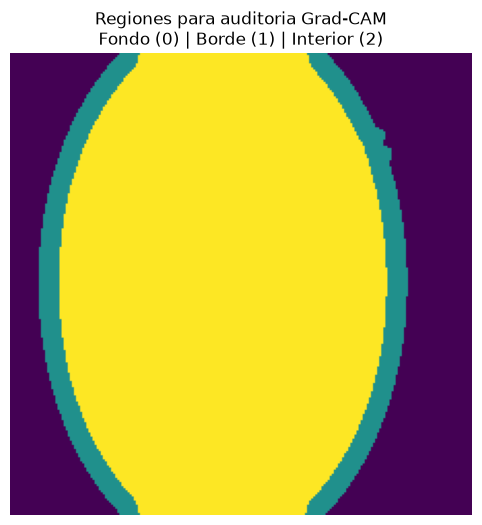

In [94]:

# ============================================================
# AUDITORIA GRAD-CAM: BORDE VS INTERIOR RETINAL
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import distance_transform_edt

# Usar mascara y activaciones previamente calculadas
mask = np.asarray(retina_mask, dtype=bool)

cam = np.maximum(
    np.asarray(cam_positive, dtype=np.float32),
    0.0
)

if cam.shape != mask.shape:
    raise ValueError(
        f"Dimensiones incompatibles: "
        f"CAM={cam.shape}, mascara={mask.shape}"
    )

# Distancia de cada pixel retinal al fondo
distance = distance_transform_edt(mask)

# Franja de 10 pixeles junto al borde
border_width = 10

border_mask = mask & (distance <= border_width)
interior_mask = mask & (distance > border_width)

total_retinal_activation = cam[mask].sum()

if total_retinal_activation <= 1e-8:
    raise ValueError(
        "No hay activacion positiva dentro de la retina."
    )

border_activation = (
    100 * cam[border_mask].sum()
    / total_retinal_activation
)

interior_activation = (
    100 * cam[interior_mask].sum()
    / total_retinal_activation
)

border_area = 100 * border_mask.sum() / mask.sum()
interior_area = 100 * interior_mask.sum() / mask.sum()

print("===== DISTRIBUCION GRAD-CAM RETINAL =====")

print(f"Area del borde: {border_area:.2f}%")
print(f"Area interior: {interior_area:.2f}%")

print(
    f"Activacion en borde: "
    f"{border_activation:.2f}%"
)

print(
    f"Activacion interior: "
    f"{interior_activation:.2f}%"
)

# Visualizacion de las regiones analizadas
region_map = np.zeros(mask.shape, dtype=np.uint8)
region_map[border_mask] = 1
region_map[interior_mask] = 2

plt.figure(figsize=(6, 6))
plt.imshow(region_map, cmap="viridis", vmin=0, vmax=2)
plt.title(
    "Regiones para auditoria Grad-CAM\n"
    "Fondo (0) | Borde (1) | Interior (2)"
)
plt.axis("off")
plt.show()


In [95]:

# ============================================================
# 18. AUDITORIA DE MASCARAS DE LESIONES IDRiD
# ============================================================

from pathlib import Path
import pandas as pd
import re

# ============================================================
# 1. DIRECTORIO DE BUSQUEDA
# ============================================================

# Si las mascaras estan fuera de DATA_DIR,
# cambia esta ruta por su ubicacion real.

SEGMENTATION_ROOT = (
    Path(DATA_DIR)
    if "DATA_DIR" in globals()
    else Path.cwd()
)

if not SEGMENTATION_ROOT.exists():
    raise FileNotFoundError(
        f"No existe: {SEGMENTATION_ROOT}"
    )

print("Buscando en:", SEGMENTATION_ROOT)

# ============================================================
# 2. LOCALIZAR MASCARAS
# ============================================================

pattern = re.compile(
    r"^(.+)_(MA|HE|EX|SE)\.(tif|tiff)$",
    re.IGNORECASE
)

mask_index = {}
mask_count = 0

for path in SEGMENTATION_ROOT.rglob("*"):

    if not path.is_file():
        continue

    match = pattern.match(path.name)

    if match is None:
        continue

    image_id = match.group(1)
    lesion_type = match.group(2).upper()

    mask_index.setdefault(image_id, {})

    if lesion_type in mask_index[image_id]:
        raise ValueError(
            f"Mascaras duplicadas para "
            f"{image_id} / {lesion_type}"
        )

    mask_index[image_id][lesion_type] = path
    mask_count += 1

print("\n===== MASCARAS ENCONTRADAS =====")
print("Archivos:", mask_count)
print("Imagenes anotadas:", len(mask_index))

# ============================================================
# 3. COMPROBAR COINCIDENCIA CON VALIDACION
# ============================================================

mask_audit = val_results.copy()

mask_audit["image_id"] = (
    mask_audit["image_path"]
    .astype(str)
    .map(lambda value: Path(value).stem)
)

mask_audit["lesions_available"] = (
    mask_audit["image_id"].map(
        lambda image_id: ",".join(
            sorted(mask_index.get(image_id, {}).keys())
        )
    )
)

mask_audit["has_masks"] = (
    mask_audit["lesions_available"].str.len() > 0
)

print("\n===== COINCIDENCIA CON VALIDACION =====")

print("Imagenes evaluadas:", len(mask_audit))
print(
    "Imagenes con mascaras:",
    int(mask_audit["has_masks"].sum())
)

print("\nEjemplos de anotaciones:")
print(list(mask_index.keys())[:10])

print("\nEjemplos de imagenes evaluadas:")
print(mask_audit["image_id"].head(10).tolist())

if mask_audit["has_masks"].any():

    display(
        mask_audit.loc[
            mask_audit["has_masks"],
            [
                "image_id",
                "patient_id",
                "binary_label",
                "lesions_available"
            ]
        ].head(15)
    )

else:
    print(
        "\nNo se encontraron mascaras que "
        "coincidan exactamente con las "
        "imagenes de validacion."
    )


Buscando en: C:\Users\lauri\Documents\PROYECTO_FINAL\data

===== MASCARAS ENCONTRADAS =====
Archivos: 0
Imagenes anotadas: 0

===== COINCIDENCIA CON VALIDACION =====
Imagenes evaluadas: 83
Imagenes con mascaras: 0

Ejemplos de anotaciones:
[]

Ejemplos de imagenes evaluadas:
['IDRiD_003', 'IDRiD_012', 'IDRiD_028', 'IDRiD_029', 'IDRiD_031', 'IDRiD_040', 'IDRiD_045', 'IDRiD_046', 'IDRiD_052', 'IDRiD_053']

No se encontraron mascaras que coincidan exactamente con las imagenes de validacion.


In [92]:

# ============================================================
# GRAD-CAM CAPSULENET - VISUALIZACION CORREGIDA
# ============================================================

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


def show_capsule_gradcam(
    model,
    image_path,
    true_label=None,
    predicted_label=None,
    probability=None,
    error_type=None,
    alpha=0.40,
    **kwargs
):

    # ========================================================
    # 1. CARGAR Y PREPROCESAR IMAGEN
    # ========================================================

    image = decode_and_preprocess(
        tf.constant(str(image_path))
    )

    batch = image[None, ...]


    # ========================================================
    # 2. CALCULAR GRAD-CAM
    # ========================================================

    heatmap, score = capsule_gradcam(
        model,
        batch
    )


    # ========================================================
    # 3. CORREGIR DIMENSIONES DEL HEATMAP
    # ========================================================

    heatmap = tf.convert_to_tensor(
        heatmap,
        dtype=tf.float32
    )

    # Eliminar dimensiones unitarias
    heatmap = tf.squeeze(heatmap)

    if heatmap.shape.rank != 2:
        raise ValueError(
            f"Grad-CAM debe ser 2D. "
            f"Forma recibida: {heatmap.shape}"
        )

    # IMG_SIZE SE UTILIZA UNA SOLA VEZ
    heatmap = tf.image.resize(
        heatmap[None, ..., None],
        size=IMG_SIZE,
        method="bilinear"
    )[0, :, :, 0]

    # Normalizar mapa de calor
    heatmap = tf.maximum(heatmap, 0.0)

    heatmap = heatmap / (
        tf.reduce_max(heatmap) + 1e-8
    )

    heatmap = heatmap.numpy()


    # ========================================================
    # 4. PREPARAR IMAGEN PARA VISUALIZACION
    # ========================================================

    image_display = image.numpy().astype(np.float32)

    # Normalizacion para mostrar la imagen
    if image_display.max() > 1.0:
        image_display = image_display / 255.0

    image_display = np.clip(
        image_display,
        0.0,
        1.0
    )


    # ========================================================
    # 5. IDENTIFICAR CASO
    # ========================================================

    image_name = Path(image_path).name

    label_names = {
        0: "No referible",
        1: "Referible"
    }

    true_text = (
        label_names.get(int(true_label), str(true_label))
        if true_label is not None
        else "No disponible"
    )

    predicted_text = (
        label_names.get(
            int(predicted_label),
            str(predicted_label)
        )
        if predicted_label is not None
        else "No disponible"
    )


    # ========================================================
    # 6. VISUALIZAR GRAD-CAM
    # ========================================================

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(15, 5)
    )

    # Imagen original
    axes[0].imshow(image_display)
    axes[0].set_title("Imagen original")
    axes[0].axis("off")

    # Mapa Grad-CAM
    axes[1].imshow(
        heatmap,
        cmap="jet",
        vmin=0,
        vmax=1
    )
    axes[1].set_title("Mapa Grad-CAM")
    axes[1].axis("off")

    # Superposicion
    axes[2].imshow(image_display)
    axes[2].imshow(
        heatmap,
        cmap="jet",
        alpha=alpha,
        vmin=0,
        vmax=1
    )
    axes[2].set_title("Grad-CAM superpuesto")
    axes[2].axis("off")

    title = (
        f"Imagen: {image_name}\n"
        f"Real: {true_text} | "
        f"Prediccion: {predicted_text}"
    )

    if error_type is not None:
        title += f" | Caso: {error_type}"

    if probability is not None:
        title += f" | Score: {float(probability):.4f}"

    fig.suptitle(
        title,
        fontsize=11
    )

    plt.tight_layout()
    plt.show()

    return heatmap


Modelo: ClinicalCapsuleNet
Capa Grad-CAM: primary_caps_conv
Umbral: 0.4272204339504242

===== CASOS DISPONIBLES =====
case_type
TP    48
TN    25
FP     6
FN     4
Name: count, dtype: int64


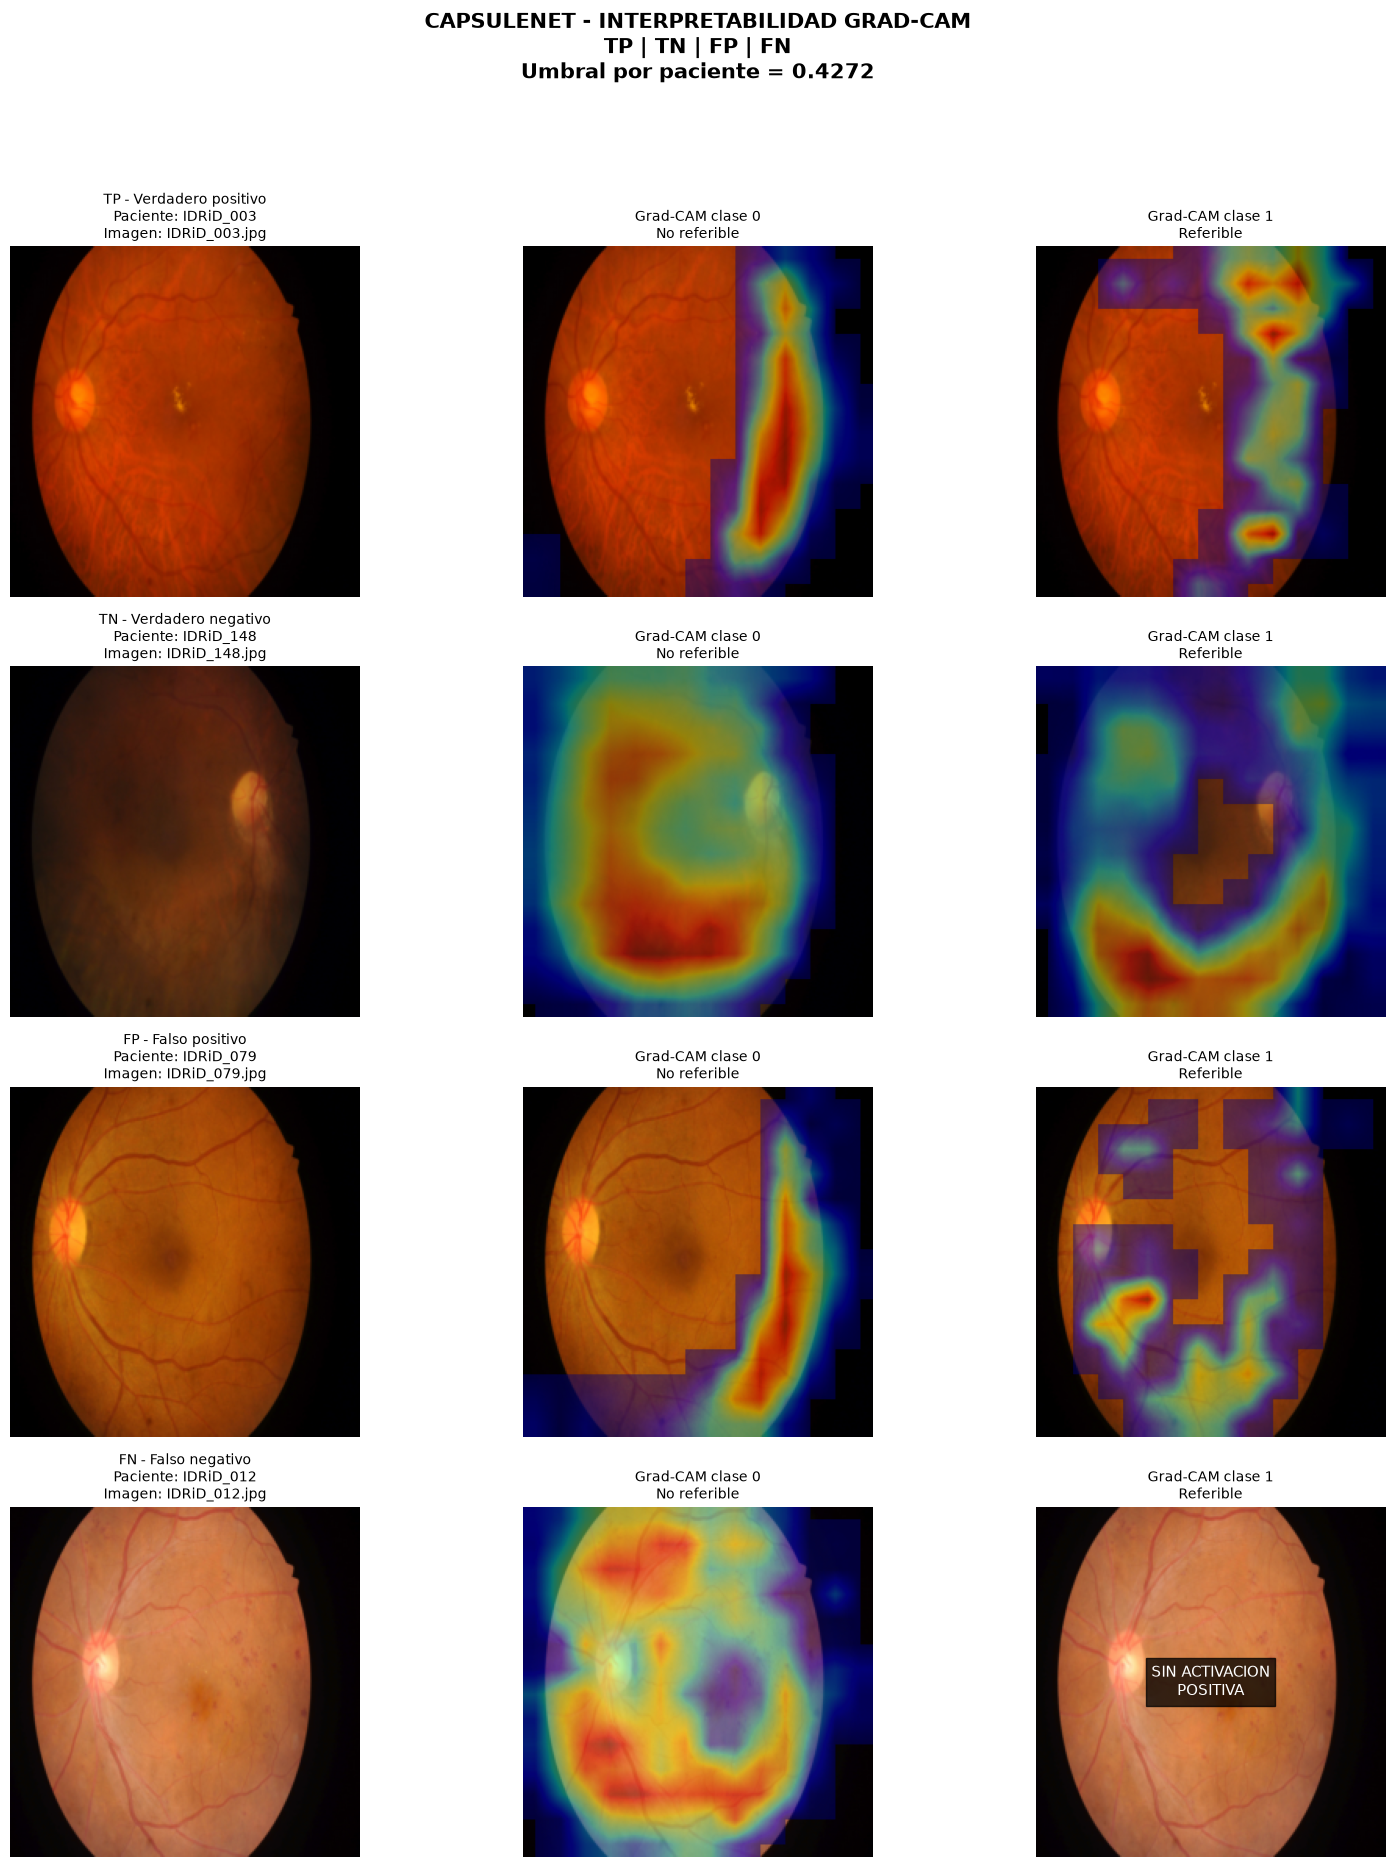


===== RESUMEN GRAD-CAM =====


,case_type,patient_id,image_name,real_label,predicted_label,patient_probability,view_probability,threshold,capsule_score_0,capsule_score_1,gradient_max_0,gradient_max_1,positive_cam_0,positive_cam_1
0,TP,IDRiD_003,IDRiD_003.jpg,1,1,0.7500,0.7500,0.4272,0.2961,0.8886,0.0034,0.0005,True,True
1,TN,IDRiD_148,IDRiD_148.jpg,0,0,0.0698,0.0698,0.4272,0.8250,0.0619,0.0013,0.0019,True,True
2,FP,IDRiD_079,IDRiD_079.jpg,0,1,0.7733,0.7733,0.4272,0.2530,0.8632,0.0032,0.0006,True,True
3,FN,IDRiD_012,IDRiD_012.jpg,1,0,0.3181,0.3181,0.4272,0.6853,0.3197,0.0025,0.0039,True,False



Visualizacion finalizada.


In [100]:

# ============================================================
# 20. GRAD-CAM CAPSULENET - TP, TN, FP, FN
# CLASIFICACION BINARIA DE RETINOPATIA DIABETICA
# ============================================================

import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# 1. CONFIGURACION
# ============================================================

CONV_LAYER_NAME = "primary_caps_conv"

CLASS_NAMES = {
    0: "No referible",
    1: "Referible"
}

CASE_NAMES = {
    "TP": "Verdadero positivo",
    "TN": "Verdadero negativo",
    "FP": "Falso positivo",
    "FN": "Falso negativo"
}

print("Modelo:", best_model.name)
print("Capa Grad-CAM:", CONV_LAYER_NAME)
print("Umbral:", SELECTED_THRESHOLD)

# ============================================================
# 2. CREAR MODELO PARA GRADIENTES
# ============================================================

conv_layer = best_model.get_layer(
    CONV_LAYER_NAME
)

grad_model = tf.keras.Model(
    inputs=best_model.inputs,
    outputs=[
        conv_layer.output,
        best_model.output
    ]
)

# ============================================================
# 3. FUNCION GRAD-CAM POR CLASE
# ============================================================

def calculate_capsule_gradcam(
    image_batch,
    class_index
):

    with tf.GradientTape() as tape:

        conv_outputs, capsule_lengths = grad_model(
            image_batch,
            training=False
        )

        # Longitud de la capsula de la clase
        class_score = tf.reduce_sum(
            capsule_lengths[:, class_index]
        )

    gradients = tape.gradient(
        class_score,
        conv_outputs
    )

    if gradients is None:
        raise ValueError(
            "No se pudieron calcular gradientes."
        )

    if conv_outputs.shape.rank != 4:
        raise ValueError(
            "La salida convolucional debe ser 4D."
        )

    tf.debugging.assert_all_finite(
        gradients,
        "Gradientes con NaN o infinito"
    )

    # Pesos de importancia por canal
    weights = tf.reduce_mean(
        gradients,
        axis=(1, 2),
        keepdims=True
    )

    # Mapa ponderado
    raw_cam = tf.reduce_sum(
        conv_outputs * weights,
        axis=-1
    )[0]

    # Contribuciones positivas
    heatmap = tf.nn.relu(raw_cam)

    # Redimensionar con IMG_SIZE
    heatmap = tf.image.resize(
        heatmap[None, ..., None],
        size=IMG_SIZE,
        method="bilinear"
    )[0, :, :, 0]

    heatmap = heatmap.numpy()

    # Normalizar sin crear activaciones artificiales
    maximum = np.max(heatmap)

    if maximum > 0:
        heatmap = heatmap / maximum
    else:
        heatmap = np.zeros_like(heatmap)

    return (
        heatmap,
        float(class_score.numpy()),
        float(tf.reduce_max(tf.abs(gradients)).numpy())
    )


# ============================================================
# 4. PREPARAR RESULTADOS POR PACIENTE
# ============================================================

patients = patient_results.copy()
views = val_results.copy()

patients["patient_id"] = (
    patients["patient_id"].astype(str)
)

views["patient_id"] = (
    views["patient_id"].astype(str)
)

patients["predicted_label"] = (
    patients["probability_mean"] >= SELECTED_THRESHOLD
).astype(int)

# Identificar TP, TN, FP y FN
def identify_case(row):

    actual = int(row["binary_label"])
    predicted = int(row["predicted_label"])

    if actual == 1 and predicted == 1:
        return "TP"

    if actual == 0 and predicted == 0:
        return "TN"

    if actual == 0 and predicted == 1:
        return "FP"

    return "FN"


patients["case_type"] = patients.apply(
    identify_case,
    axis=1
)

print("\n===== CASOS DISPONIBLES =====")
print(patients["case_type"].value_counts())

# ============================================================
# 5. SELECCIONAR UN PACIENTE POR CADA CASO
# ============================================================

selected_cases = []

for case_type in ["TP", "TN", "FP", "FN"]:

    candidates = patients[
        patients["case_type"] == case_type
    ]

    if candidates.empty:
        print(
            f"No existen pacientes tipo {case_type}"
        )
        continue

    # Seleccion reproducible por identificador
    patient = candidates.sort_values(
        "patient_id"
    ).iloc[0]

    patient_views = views[
        views["patient_id"] == patient["patient_id"]
    ].copy()

    if patient_views.empty:
        raise ValueError(
            f"No hay imagenes de "
            f"{patient['patient_id']}"
        )

    # Elegir la imagen cuya puntuacion sea
    # mas cercana a la media del paciente
    patient_views["distance"] = np.abs(
        patient_views["probability"]
        - patient["probability_mean"]
    )

    selected_view = patient_views.sort_values(
        "distance"
    ).iloc[0]

    selected_cases.append(
        (case_type, patient, selected_view)
    )

# ============================================================
# 6. VISUALIZAR LOS CUATRO CASOS
# ============================================================

fig, axes = plt.subplots(
    4,
    3,
    figsize=(16, 19)
)

gradcam_case_results = []

# Desactivar filas inicialmente
for ax in axes.flat:
    ax.axis("off")

for row, (case_type, patient, view) in enumerate(
    selected_cases
):

    image_path = str(view["image_path"])

    # Cargar la imagen usada por CapsuleNet
    image = decode_and_preprocess(
        tf.constant(image_path)
    )

    image = tf.cast(image, tf.float32)
    batch = image[None, ...]

    # Grad-CAM clase 0
    heatmap_0, score_0, grad_0 = (
        calculate_capsule_gradcam(
            batch,
            class_index=0
        )
    )

    # Grad-CAM clase 1
    heatmap_1, score_1, grad_1 = (
        calculate_capsule_gradcam(
            batch,
            class_index=1
        )
    )

    # Imagen para mostrar
    image_display = image.numpy().copy()

    if image_display.min() < 0:

        if image_display.min() >= -1 and image_display.max() <= 1:
            image_display = (image_display + 1) / 2
        else:
            image_display = (
                image_display - image_display.min()
            ) / (np.ptp(image_display) + 1e-8)

    elif image_display.max() > 1:
        image_display = image_display / 255.0

    image_display = np.clip(
        image_display,
        0,
        1
    )

    # ========================================================
    # COLUMNA 1: IMAGEN
    # ========================================================

    axes[row, 0].imshow(image_display)

    axes[row, 0].set_title(
        f"{case_type} - {CASE_NAMES[case_type]}\n"
        f"Paciente: {patient['patient_id']}\n"
        f"Imagen: {Path(image_path).name}",
        fontsize=10
    )

    # ========================================================
    # COLUMNA 2 Y 3: GRAD-CAM DE CADA CLASE
    # ========================================================

    for col, (heatmap, class_index) in enumerate(
        [(heatmap_0, 0), (heatmap_1, 1)],
        start=1
    ):

        axes[row, col].imshow(image_display)

        if np.max(heatmap) > 0:

            # Mostrar solo contribuciones positivas
            visible_cam = np.ma.masked_less_equal(
                heatmap, 0
            )

            axes[row, col].imshow(
                visible_cam,
                cmap="jet",
                alpha=0.45,
                vmin=0,
                vmax=1
            )

        else:

            axes[row, col].text(
                0.5,
                0.5,
                "SIN ACTIVACION\nPOSITIVA",
                transform=axes[row, col].transAxes,
                ha="center",
                va="center",
                color="white",
                fontsize=11,
                bbox=dict(
                    facecolor="black",
                    alpha=0.75
                )
            )

        axes[row, col].set_title(
            f"Grad-CAM clase {class_index}\n"
            f"{CLASS_NAMES[class_index]}",
            fontsize=10
        )

    for ax in axes[row]:
        ax.axis("off")

    # ========================================================
    # GUARDAR RESULTADOS DEL CASO
    # ========================================================

    gradcam_case_results.append({

        "case_type": case_type,
        "patient_id": patient["patient_id"],
        "image_name": Path(image_path).name,

        "real_label": int(patient["binary_label"]),
        "predicted_label": int(patient["predicted_label"]),

        "patient_probability": float(
            patient["probability_mean"]
        ),

        "view_probability": float(
            view["probability"]
        ),

        "threshold": float(SELECTED_THRESHOLD),

        "capsule_score_0": score_0,
        "capsule_score_1": score_1,

        "gradient_max_0": grad_0,
        "gradient_max_1": grad_1,

        "positive_cam_0": bool(np.max(heatmap_0) > 0),
        "positive_cam_1": bool(np.max(heatmap_1) > 0),
    })


# ============================================================
# 7. TITULO GENERAL
# ============================================================

fig.suptitle(
    "CAPSULENET - INTERPRETABILIDAD GRAD-CAM\n"
    "TP | TN | FP | FN\n"
    f"Umbral por paciente = {SELECTED_THRESHOLD:.4f}",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout(
    rect=[0, 0, 1, 0.94]
)

plt.show()


# ============================================================
# 8. TABLA RESUMEN
# ============================================================

gradcam_results_df = pd.DataFrame(
    gradcam_case_results
)

print("\n===== RESUMEN GRAD-CAM =====")

display(gradcam_results_df.round(4))

print("\nVisualizacion finalizada.")


In [85]:

# ============================================================
# DIAGNOSTICO DE PREDICCION CAPSULENET
# ============================================================

import tensorflow as tf
import numpy as np

image_path = selected_view["image_path"]

image = decode_and_preprocess(
    tf.constant(str(image_path))
)

batch = image[None, ...]

capsule_lengths = best_model(
    batch,
    training=False
).numpy()[0]

score_referible = (
    capsule_lengths[1] /
    (np.sum(capsule_lengths) + 1e-7)
)

predicted_label = int(
    score_referible >= SELECTED_THRESHOLD
)

print("===== PREDICCION POR IMAGEN =====")

print("Imagen:", image_path)

print(
    "Longitud capsula No referible:",
    float(capsule_lengths[0])
)

print(
    "Longitud capsula Referible:",
    float(capsule_lengths[1])
)

print(
    "Puntuacion normalizada Referible:",
    round(float(score_referible), 4)
)

print(
    "Umbral utilizado:",
    SELECTED_THRESHOLD
)

print(
    "Prediccion:",
    "Referible" if predicted_label == 1
    else "No referible"
)


===== PREDICCION POR IMAGEN =====
Imagen: C:\Users\lauri\Documents\PROYECTO_FINAL\data\IDRiD2\IDRiD\train\images\IDRiD_012.jpg
Longitud capsula No referible: 0.6852713823318481
Longitud capsula Referible: 0.3196641206741333
Puntuacion normalizada Referible: 0.3181
Umbral utilizado: 0.4272204339504242
Prediccion: No referible


In [84]:
# 21. PREDECIR UNA NUEVA IMAGEN

def predict_fundus_image(
    model,
    image_path,
    threshold,
    show_gradcam=True,
):
    image = decode_and_preprocess(tf.constant(str(image_path)))
    lengths = model(image[None, ...], training=False).numpy()[0]

    probability = float(
        lengths[1] / (lengths.sum() + 1e-7)
    )
    prediction = int(probability >= threshold)

    result = {
        "image_path": str(image_path),
        "probability_referable": probability,
        "threshold": float(threshold),
        "prediction": prediction,
        "interpretation": (
            "RDR referible"
            if prediction == 1
            else "No referible"
        ),
    }

    if show_gradcam:
        show_capsule_gradcam(
            model,
            image_path,
            threshold=threshold,
        )

    return result


# Ejemplo:
# result = predict_fundus_image(
#     best_model,
#     "/content/nueva_imagen.jpg",
#     SELECTED_THRESHOLD,
# )
# print(json.dumps(result, indent=2, ensure_ascii=False))